# <center> Сегментация клиентов онлайн магазина подарков

## 1. Знакомство с данными, базовый анализ

**Описание проекта и бизнес-контекст**

Данное исследование посвящено автоматизации маркетинговых стратегий и оптимизации взаимодействия с клиентами в сфере электронной коммерции (E-commerce). В условиях жесткой конкуренции массовые рекламные рассылки неэффективно расходуют бюджет. Цель проекта — разработка интеллектуального алгоритма для **интеллектуальной сегментации клиентской базы онлайн-магазина подарков.**

В качестве исходных данных используется исторический массив транзакций крупной торговой платформы, обслуживающей как розничных, так и оптовых клиентов. Анализ реальных поведенческих факторов позволяет гибко реагировать на изменения активности покупателей практически в режиме реального времени.

**Бизнес-задача:** произвести сегментацию существующих клиентов на основе их покупательской активности, детально проинтерпретировать выделенные когорты и определить индивидуальную стратегию взаимодействия с каждой группой для роста LTV и удержания клиентов.

**Техническая задача (Data Science):** Построение устойчивой модели машинного обучения для решения задачи кластеризации — разделения клиентской базы на группы на основе давности покупок (Recency), их частоты (Frequency) и монетарной ценности (Monetary), с последующей валидацией качества разбиения и описанием профиля каждого кластера.

**Этапы реализации кейса:**

1. Первичная обработка и очистка исходного набора данных о транзакциях.
2. Разведывательный анализ данных (Exploratory Data Analysis) и бизнес-валидация.
3. Feature Engineering: Построение RFM-витрины и фильтрация выбросов.
4. Машинное обучение, валидация алгоритмов и профилирование кластеров
5. Заключение и итоги реализации проекта.

## Данные и их описание

Данные представляют собой таблицу в формате CSV, в каждой строке которой содержится информация об уникальной транзакции.

Признаки, описывающие каждую транзакцию:

* **InvoiceNo** — номер счёта-фактуры (уникальный номинальный шестизначный номер, присваиваемый каждой транзакции; буква "C" в начале кода указывает на отмену транзакции);
* **StockCode** — код товара (уникальное пятизначное целое число, присваиваемое каждому отдельному товару);
* **Description** — Описание товара, транзакции или название товара;
* **Quantity** — количество каждого товара за транзакцию;
* **InvoiceDate** — дата и время выставления счёта/проведения транзакции;
* **UnitPrice** — цена за единицу товара в фунтах стерлингов;
* **CustomerID** — идентификатор клиента (уникальный пятизначный номер, однозначно присваиваемый каждому клиенту);
* **Country** — название страны, в которой проживает клиент.

#### Импорт базовых библиотек

In [74]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

import plotly.graph_objs as go
import plotly.express as px
from plotly.subplots import make_subplots

import warnings 
warnings.filterwarnings("ignore")

from IPython.display import display, HTML

plt.rcParams["patch.force_edgecolor"] = True

## 1. Первичная обработка и очистка исходного набора данных о транзакциях

### 1.1. Знакомство со структурой данных

In [75]:
customer_info = pd.read_csv(
    'data/data.csv', 
    encoding = "ISO-8859-1", 
    dtype = {'CustomerID': str, 'InvoiceNo': str}
)
# Посмотрим на первые пять строк исходного набора данных
customer_info.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850,United Kingdom


#### Оценим общую структуру набора данных, типы переменных и наличие пропущенных значений для формирования стратегии предобработки.

In [76]:
# Сводка по DataFrame: столбцы, типы, non-null и память
customer_info.info()

print('='*45)
# Выясним, сколько всего пропусков в датасете
print(f'Общее количество пропусков в датасете: {customer_info.isnull().sum().sum()}')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  object 
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB
Общее количество пропусков в датасете: 136534


#### Результаты первичного анализа структуры данных:

1. **Масштаб данных:** Набор данных содержит **541 909 наблюдений** и **8 целевых признаков**, что обеспечивает достаточную репрезентативность для построения моделей кластеризации.
2. **Спецификация типов:** Признаки распределены как `int64` (1), `float64` (1) и `object` (6). Отмечается необходимость приведения временного признака `InvoiceDate` к формату `datetime` для корректного расчета метрик давности (Recency).
3. **Критический дефицит данных (Пропуски):** 
   * Признак `Description` имеет незначительное число пропусков (около 0.2%).
   * Признак `CustomerID` содержит **более 135 000 пропущенных значений** (~25% от всего датасета). Поскольку идентификатор клиента является ключевым для расчета RFM-метрик и последующей сегментации, обработка этого подмножества данных станет приоритетной задачей на этапе очистки.

In [77]:
# Перед началом преобразований скопируем основной датасет в новую переменную
df_sales = customer_info.copy()

# Преобразуем признак InvoiceDate в формат datetime
df_sales['InvoiceDate'] = pd.to_datetime(df_sales['InvoiceDate'])

# Определим дату начала занесения информации в датасет
df_start = df_sales['InvoiceDate'].dt.date.min()

# Определим дату последней записи в датасете
df_last = df_sales['InvoiceDate'].dt.date.max()

# Выведем на печать период, за который в датасете представлена информация
print("Данные представлены за следующий период:")
print(f'c {df_start} по {df_last} включительно')

Данные представлены за следующий период:
c 2010-12-01 по 2011-12-09 включительно


### Проведем первичный дескриптивный анализ (описательная статистика)

Выполним экспресс-анализ категориальных признаков в сыром датасете. На данном этапе это необходимо для верхнеуровневой оценки масштаба данных и структуры пропусков перед запуском пайплайна очистки. Полные бизнес-выводы по распределению клиентов будут сделаны после удаления некорректных записей.

In [78]:
# Расчет ключевых статистических показателей:
display(df_sales.describe())
print('='*80)
display(df_sales.describe(include='object').T)
print('='*72)

# Выведем Топ-20 самых активных стран
countries = df_sales['Country'].value_counts().head(20)
countries

,Quantity,InvoiceDate,UnitPrice
count,541909.000000,541909,541909.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114
min,-80995.000000,2010-12-01 08:26:00,-11062.060000
25%,1.000000,2011-03-28 11:34:00,1.250000
50%,3.000000,2011-07-19 17:17:00,2.080000
75%,10.000000,2011-10-19 11:27:00,4.130000
max,80995.000000,2011-12-09 12:50:00,38970.000000
std,218.081158,NaN,96.759853


,count,unique,top,freq
InvoiceNo,541909,25900,573585,1114
StockCode,541909,4070,85123A,2313
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369
CustomerID,406829,4372,17841,7983
Country,541909,38,United Kingdom,495478


Country
United Kingdom     495478
Germany              9495
France               8557
EIRE                 8196
Spain                2533
Netherlands          2371
Belgium              2069
Switzerland          2002
Portugal             1519
Australia            1259
Norway               1086
Italy                 803
Channel Islands       758
Finland               695
Cyprus                622
Sweden                462
Unspecified           446
Austria               401
Denmark               389
Japan                 358
Name: count, dtype: int64

In [79]:
# Рассчитаем среднюю стоимость товара в фунтах стерлингов до очистки датасета
print(f"Средняя стоимость товара составляет: {df_sales['UnitPrice'].mean():.2f} £")

Средняя стоимость товара составляет: 4.61 £


### 1.2. Преобразование, очистка и анализ данных

#### 1.2.1 Пропуски

Идентификатор клиента (`CustomerID`) является ключевым связующим признаком для агрегации транзакций и последующего расчета метрик Recency, Frequency и Monetary. Восстановление пропущенных ID (около 25% датасета) с помощью статистических методов (мода, заглушки) невозможно, так как это приведет к искусственному искажению реального покупательского поведения и некорректной кластеризации. 

Единственным корректным решением с точки зрения Data Science является исключение транзакций с неизвестными пользователями из анализируемого массива данных.

In [80]:
# Удаление строк с пропущенными значениями в CustomerID
df_sales = df_sales.dropna(subset=['CustomerID'])

In [81]:
# После удаления пропусков, проверяем сколько пропусков осталось в датасете
print(f'Оставшееся количество пропусков в датасете: {df_sales.isnull().sum().sum()}')

Оставшееся количество пропусков в датасете: 0


#### Результаты обработки пропусков:
* Транзакции без привязки к `CustomerID` успешно исключены из датасета.
* Текущий размер выборки полностью очищен от пропусков. Удалив строки с пропусками в признаке CustomerID, мы также избавились от пропусков в признаке Description

#### 1.2.2. Дубликаты

Наличие полных дубликатов строк в транзакциях часто сигнализирует о технических сбоях при выгрузке данных (например, повторная отправка HTTP-запроса). Перед очисткой оценим объем избыточных данных, чтобы убедиться в отсутствии системных ошибок при формировании датасета.

In [82]:
# Проверим датасет на наличие дубликатов
duplicate_count = df_sales.duplicated().sum()
print(f'Количество дубликатов в датасете = {duplicate_count}')

Количество дубликатов в датасете = 5225


На этапе экспресс-анализа было выявлено **5 225 избыточных строк-копий**. Для понимания природы данных важно дифференцировать технический сбой (ошибки логирования) от бизнес-процессов (дробление оптовых партий на складе, повторные клики пользователей в интерфейсе). 

Отберем строки с дубликатами, чтобы посмотреть на их структуру, а затем удалим лишние копии из таблицы.

In [83]:
# Находим все одинаковые строки (включая оригиналы) и сортируем по номеру чека и товара
mask = df_sales.duplicated(keep=False)
df_dupl = df_sales[mask].sort_values(by=['InvoiceNo', 'StockCode'])

# Считаем основные показатели, чтобы понять природу дубликатов
print(f'Всего строк вовлеченных в дублирование (вместе с оригиналами): {df_dupl.shape[0]}')
print(f"Количество уникальных инвойсов: {df_dupl['InvoiceNo'].nunique()}")
print(f"\nТоп-5 стран в которых дублировались чеки:\n{df_dupl['Country'].value_counts().head()}")

print('='*71)
# Смотрим глазами на табличку дубликатов
display(df_dupl.head(6))

Всего строк вовлеченных в дублирование (вместе с оригиналами): 10062
Количество уникальных инвойсов: 1903

Топ-5 стран в которых дублировались чеки:
Country
United Kingdom    9914
France              32
Germany             30
Cyprus              21
EIRE                20
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908,United Kingdom


#### Результаты анализа дубликатов:

* **Масштаб и структура:** Всего в дублировании участвует 10 062 строки в 1 903 разных чеках. В среднем на один проблемный чек приходится по 4–5 повторяющихся строк. Это говорит о том, что сбой происходил целыми пакетами товаров внутри одного заказа, а не единичными строчками.
* **География данных:** Почти все дубликаты (более 98%) приходятся на Великобританию (`United Kingdom`), что логично для домашнего рынка компании. 
* **Аномалия на Кипре:** При анализе топ-5 стран обнаружилась скрытая проблема. У Кипра (`Cyprus`) очень мало заказов во всей базе (всего 622), но он попал в топ по дубликатам (21 строка). Это значит, что для клиентов из Кипра система сбоила в 10 раз чаще, чем для Германии или Франции. Это важный сигнал для IT-отдела проверить работу платежного шлюза или сайта для этого региона.
* **Итог:** Удаление этих строк методом `.drop_duplicates()` полностью обосновано. Мы очистим базу от технического шума и сможем дальше работать с чистыми данными.

In [84]:
# Удаляем дубликаты
df_sales = df_sales.drop_duplicates()

# # Проверяем, что в датасете не осталось дубликатов
duplicate_count = df_sales.duplicated().sum()
print(f'Количество дубликатов после удаления = {duplicate_count}')

Количество дубликатов после удаления = 0


In [85]:
amt_str = df_sales.shape[0]
print(f'Количество строк в датасете после удаления пропусков и дубликатов: {amt_str}')

Количество строк в датасете после удаления пропусков и дубликатов: 401604


#### 1.2.3. Транзакции с отрицательным количеством товара

Мы знаем что учет возвратов товаров, отмены заказов и скидок на товар в компании осуществляется  особым образом. Когда мы будем сегментировать клиентов, мы будем определять их покупательскую способность. При расчёте покупательской способности нам будет очень важно учесть возвраты этого клиента, а так же скидки предоставленные ему.

Чтобы подсчитать количество возвратов, для начала нам надо определить, сколько уникальных товаров указано в транзакции (корзине) для каждой уникальной пары «клиент — заказ»:


In [86]:
# Сгруппируем данные по клиентам и закзам для определения активности клиента
sku_invoice = df_sales.groupby(
    by =['CustomerID', 'InvoiceNo'], as_index=False)['StockCode'].nunique()

# Переименуем колонки для наглядности
sku_invoice = sku_invoice.rename(columns={'StockCode': 'Number of Products'})
sku_invoice.head()

,CustomerID,InvoiceNo,Number of Products
0,12346,541431,1
1,12346,C541433,1
2,12347,537626,31
3,12347,542237,29
4,12347,549222,24


В розничной торговле клиенты часто возвращают товары или отменяют заказы. В нашем датасете возвраты оформлены как отдельные строки с отрицательным количеством товара (`Quantity < 0`). 

Чтобы корректно посчитать чистую прибыль и реальный объем покупок для каждого клиента, нам нужно связать возвраты с их оригинальными заказами. Для этого мы создадим новый признак — `QuantityCanceled` (Количество отмененного товара).

**Логика работы признака:**
* **Для успешных заказов, по которым был возврат:** в поле `QuantityCanceled` запишется то количество товара, которое клиент позже вернул.
* **Для заказов, по которым возвратов не было:** признак будет равен `0`.
* **Сами строки возвратов** (с отрицательным количеством) после этого расчета мы сможем исключить из анализа, так как их сумма уже будет учтена в оригинальных чеках.

##### В начале напишем вспомогательную функцию *get_quantity_canceled()*. Эта функция принимает на вход DataFrame с транзакциями и возвращает объект `Series` — столбец, в котором указано количество отменённого впоследствии товара для каждой транзакции. Если транзакция не имеет контрагента, этот признак помечается как `NaN`

In [87]:
def get_quantity_canceled(df):
    
    """Вспомогательная функция для создания признака 
    QuantityCanceled (количество отмененных заказов).
    Данная функция принимает на вход датасет с транзакциями и возвращает столбец 
    в котором указано количество отменённого впоследствии товара для каждой транзакции.
    Если транзакция с отрицательным количеством товара не имеет контрагента, 
    данный признак помечается как NaN.

    Args:
        df (DataFrame): датасет с транзакциями
        
    Returns:
        Series: столбец с количеством отмененного товара
    """
    # Инициализируем обект Series заполненный нулями
    quantity_canceled = pd.Series(np.zeros(df.shape[0]), index=df.index)
    
    # Выделим из представленного df строки с отрицательным количеством товаров
    # и оформим его в виде DataFrame 
    negative_canceled = df[df['Quantity'] < 0].copy()
    
    # Запускаем цикл построчного перебора DF с возвратами
    for in_x, col in negative_canceled.iterrows():
        
        # Находим все УСПЕШНЫЕ покупки (Quantity > 0) клиента по его товару,
        # совершенные СТРОГО РАНЬШЕ даты отмены
        df_test = df[(df['CustomerID'] == col['CustomerID']) &
                     (df['StockCode'] == col['StockCode']) &
                     (df['InvoiceDate'] < col['InvoiceDate']) &
                     (df['Quantity'] > 0)].copy()
        
        # У контрагента до отмены нет покупок, ничего не делаем
        if df_test.shape[0]	== 0:
            # Помечаем столбец как пропуск
            quantity_canceled.loc[in_x] = np.nan
        
        # У контрагента одна единственная покупка, совершенная до отмены.
        # Добавляем количество отменённого товара в quantity_canceled   
        elif df_test.shape[0] == 1:
            index_order = df_test.index[0]
            # Фиксируем объем отмены, убирая отрицательный знак
            quantity_canceled.loc[index_order] = -col['Quantity']
            
        # У этого клиента есть НЕСКОЛЬКО прошлых покупок данного товара.
        # Ищем среди них САМУЮ СВЕЖУЮ покупку, в которой купленного товара 
        # было СТОЛЬКО ЖЕ ИЛИ БОЛЬШЕ, чем возвращается сейчас.
        # Записываем объём отмены в объект-посредник для этой строки.
        elif df_test.shape[0] > 1:
            df_test = df_test.sort_index(ascending=False)
            for ind, val in df_test.iterrows():
                if val['Quantity'] < -col['Quantity']:
                    continue
                quantity_canceled.loc[ind] = -col['Quantity']
                break
    
    return quantity_canceled

In [88]:
# Создадим новую колонку QuantityCanceled в датасете df_sales
df_sales['QuantityCanceled'] = get_quantity_canceled(df_sales)

# Посмотрим на результат
df_sales.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,QuantityCanceled
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,0.0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0.0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,0.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0.0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0.0


In [89]:
# Топ-10 самых крупных возвратов
df_sales['QuantityCanceled'].sort_values(ascending=False).head(10)

540421    80995.0
61619     74215.0
52711      3114.0
52710      2000.0
52709      1930.0
223446     1515.0
384010     1296.0
371176     1200.0
169123      960.0
384007      840.0
Name: QuantityCanceled, dtype: float64

In [90]:
# Детализация по двум аномально крупным возвратам
df_sales.loc[[540421, 61619]]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,QuantityCanceled
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,80995.0
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,74215.0


#### Бизнес-вывод:

В датасете присутствуют две сверхкрупные оптовые транзакции (на 80 995 и 74 215 единиц товара), которые были полностью аннулированы покупателями. Эти операции не отражают реальный розничный или регулярный оптовый оборот компании, а являются результатом либо ошибочного ввода данных оператором, либо мгновенного отказа от сверхкрупного заказа

In [91]:
# Посчитаем количество возвратов для контрагентов у которых до возврата покупок нет.
count_returns = df_sales['QuantityCanceled'].isna().sum()
print(f"Количество возвратов без предварительных покупок: {count_returns}")

Количество возвратов без предварительных покупок: 1303


##### Количество таких возвратов составляет менее **0.5%**, поэтому мы их удалим

In [92]:
# Удаляем строки с возвратами, для которых не нашлось истории покупок
# (где QuantityCanceled равно NaN)
df_sales = df_sales.dropna(subset=['QuantityCanceled'])

In [93]:
# Проверяем количество пропусков после их удаления
print(f"Осталось пропусков: {df_sales['QuantityCanceled'].isna().sum()}")

Осталось пропусков: 0


#### Удаление изолированных записей о возвратах

После того как данные об отмененных товарах были успешно перенесены в оригинальные чеки (в признак `QuantityCanceled`), строки с отрицательным количеством товара (`Quantity < 0`) становятся избыточными. Их дальнейшее присутствие в датасете приведет к двойному учету одних и тех же операций при расчете финальных метрик. 

Очистим датасет, оставив только прямые коммерческие транзакции.

In [94]:
# Создаем маску для отбора только положительных транзакций (покупок)
mask_positive = df_sales['Quantity'] > 0

# Фильтруем датасет, удаляя строки с возвратами
df_sales = df_sales[mask_positive]

In [95]:
print('Размер датасета после удаления строк, содержащих Nan в колонке QuantityCanceled:')
print(f'Количество строк: {df_sales.shape[0]}\nКоличество столбцов: {df_sales.shape[1]}')

Размер датасета после удаления строк, содержащих Nan в колонке QuantityCanceled:
Количество строк: 392732
Количество столбцов: 9


#### 1.2.4. Специализированные транзакции

В нашем датасете помимо обычных товаров есть записи о дополнительных расходах компании. Это могут быть почтовые отправления (`POST`), транспортные затраты (`C2`) или банковские комиссии (`BANK CHARGES`). 

Такие операции не отражают реальный интерес клиента к ассортименту магазина. Чтобы они не мешали нам при сегментации, нужно найти все коды товаров (`StockCode`), которые начинаются с латинских букв, и изучить их описание.

In [96]:
# Находим все строки, которые подходят под этот шаблон (приводим к str для безопасности)
special_records = df_sales[
    df_sales['StockCode'].astype(str).str.contains('^[a-zA-Z]+', na=False)
]
# Выведем на печать количество строк с нетоварными транзакциями
print(f'Количество строк с накладными расходами: {special_records.shape[0]}')
print('='*46)
# Выводим уникальные коды и их описания, чтобы понять, что внутри
special_codes = special_records[['StockCode', 'Description']].drop_duplicates()
special_codes

Количество строк с накладными расходами: 1549


,StockCode,Description
45,POST,POSTAGE
1423,C2,CARRIAGE
2239,M,Manual
4406,BANK CHARGES,Bank Charges
157195,PADS,PADS TO MATCH ALL CUSHIONS
317507,DOT,DOTCOM POSTAGE


#### Очистка датасета от нетоварных транзакций

Мы изучили структуру найденных специальных кодов. Все они (`POST`, `C2`, `M`, `BANK CHARGES`, `PADS`, `DOT`) относятся к накладным расходам и сервисному обслуживанию. 

Чтобы эти данные не искажали профили покупателей при кластеризации, исключим их из нашей таблицы.

In [97]:
# Ставим знак ~ перед маской, чтобы оставить только обычные числовые товары
df_sales = df_sales[
    ~df_sales['StockCode'].astype(str).str.contains('^[a-zA-z]+', na=False)
]
# Проверим размер таблицы после удаления, чтобы убедиться, что "нетоварные" строки ушли
print(f'Размер датасета после удаления нетоварных строк: {df_sales.shape[0]}')

Размер датасета после удаления нетоварных строк: 391183


#### 1.2.5. Транзакции с товарами без стоимости 

При анализе цен обнаружилось небольшое количество строк, где стоимость товара равна 0 фунтов стерлингов. Такие записи составляют менее 1% от всей базы и могут быть вызваны техническими ошибками или выдачей бесплатных рекламных образцов. 

Исключим эти строки из таблицы, чтобы нулевые цены не искажали расчеты средних чеков и монетарной ценности клиентов.

In [98]:
# Создаем маску, которая оставляет только товары с ценой выше нуля
mask_positive_price = df_sales['UnitPrice'] > 0

# Фильтруем таблицу по этой маске
df_sales = df_sales[mask_positive_price]

# Проверяем минимальную цену в датасете, чтобы убедиться, что нулей не осталось
print(f"Минимальная цена товара в базе теперь равна: {df_sales['UnitPrice'].min()} £")

# Фиксируем измененияв в размера датасета
print(f'Количество строк в датасете после фильтрации: {df_sales.shape[0]}')

Минимальная цена товара в базе теперь равна: 0.04 £
Количество строк в датасете после фильтрации: 391150


#### 1.2.6. Генерация дополнительных признаков для анализа чеков

##### Новые признаки: 
* **`TotalPrice`** — общая стоимость конкретного товара в транзакции (с учетом возвратов).
* **`TotalSum`** — итоговая сумма всего чека (заказа).
* **`CountSkuCheck`** — общее количество товарных позиций в чеке.

**Зачем это нужно:**
Эти признаки помогут нам детально изучить структуру покупок. На уровне каждого заказа мы сразу увидим его общую стоимость и объем корзины. В дальнейшем это позволит алгоритму точнее разделить клиентов на розничных покупателей и крупных оптовиков.

Для расчета `TotalSum` и `CountSkuCheck` мы используем метод `.transform()`. Он удобен тем, что считает показатели для всего чека, но сохраняет исходный размер таблицы и автоматически расставляет значения по строкам.

In [99]:
# Расчет стоимости конкретной товарной позиции с учетом возвратов
df_sales['TotalPrice'] = df_sales['UnitPrice'] * (
    df_sales['Quantity'] - df_sales['QuantityCanceled'])

# Расчет общей суммы всего чека (заказа)
df_sales['TotalSum'] = df_sales.groupby(by=['InvoiceNo'])['TotalPrice'].transform('sum')

# Расчет количества товарных строк в чеке
df_sales['CountSkuCheck'] = df_sales.groupby(
    by=['InvoiceNo'])['Quantity'].transform('count')

# Проверяем результат добавления признаков
df_sales[[
    'InvoiceNo', 'CustomerID', 'Quantity', 'QuantityCanceled', 'UnitPrice', 
    'TotalPrice', 'TotalSum', 'CountSkuCheck']].head(9)

,InvoiceNo,CustomerID,Quantity,QuantityCanceled,UnitPrice,TotalPrice,TotalSum,CountSkuCheck
0,536365,17850,6,0.0,2.55,15.30,139.12,7
1,536365,17850,6,0.0,3.39,20.34,139.12,7
2,536365,17850,8,0.0,2.75,22.00,139.12,7
3,536365,17850,6,0.0,3.39,20.34,139.12,7
4,536365,17850,6,0.0,3.39,20.34,139.12,7
5,536365,17850,2,0.0,7.65,15.30,139.12,7
6,536365,17850,6,0.0,4.25,25.50,139.12,7
7,536366,17850,6,0.0,1.85,11.10,22.20,2
8,536366,17850,6,0.0,1.85,11.10,22.20,2


#### 1.2.7. Санитизация данных и фильтрация краевых аномалий

Перед переходом к разведывательному анализу (EDA) проведена проверка датасета на логическую целостность. В результате аудита были выявлены единичные технические аномалии, суммарно составляющие менее 0.5% от общего объема данных:
* **36 строк** с отрицательным показателем `TotalPrice` и **2 строки** с отрицательным `TotalSum` (коллизии из-за избыточного зачета отмен).
* **2 543 строки** с нулевой стоимостью позиции (`TotalPrice == 0`) и **911 строк** с нулевой стоимостью всего чека (`TotalSum == 0`).

**Инженерное решение:**
Подобные записи представляют собой статистический шум (тестовые логи, системные сбои или маркетинговые раздачи бесплатных образцов) и не отражают реальное экономическое поведение клиентов. Для исключения искажений при расчете средних чеков и графиков активности, данные некоммерческие строки были удалены из аналитического массива (`TotalPrice > 0` и `TotalSum > 0`).

In [100]:
# С помощью фильтрации удалим строки с нулевой стоимостью позиции
df_sales = df_sales[(df_sales['TotalPrice'] > 0) & (df_sales['TotalSum'] > 0)]

# Фиксируем измененияв в размера датасета
print(f'Количество строк в датасете после фильтрации: {df_sales.shape[0]}')

Количество строк в датасете после фильтрации: 388570


## 2. Разведывательный анализ данных (Exploratory Data Analysis) и бизнес-валидация.

**Бизнес-контекст этапа:**
Прежде чем переходить к математическому моделированию и кластеризации, необходимо исследовать сформированный массив транзакций и выявить ключевые коммерческие закономерности. Понимание географической специфики спроса и временных колебаний активности пользователей позволит корректно интерпретировать будущие сегменты и сформировать валидные гипотезы для маркетинга.

**Ключевые аналитические задачи и направления исследования:**

1. **Географический профиль клиентской базы:**
   * Оценка распределения объемов и частоты покупок в разрезе стран присутствия.
   * Выявление ключевых макрорегионов, формирующих основной поток заказов.

2. **Анализ сезонности и структуры выручки:**
   * Исследование динамики доходов компании по месяцам для выявления периодов пикового спроса (сезонности).
   * Определение стран-лидеров, обеспечивающих максимальный вклад в сезонную выручку.

3. **Исследование микросезонности и внутридневной активности:**
   * Анализ распределения заказов по дням и часам совершения транзакций.
   * Расчет среднего количества ежедневно поступающих заказов в разрезе часов для оптимизации времени маркетинговых коммуникаций и прогнозирования пиковой нагрузки на персонал и серверную инфраструктуру.

4. **Структура чеков и масштабы клиентов:**
   * Анализ показателей `TotalSum` (сумма чека) и `CountSkuCheck` (количество товаров в заказе).
   * Исследование структуры покупок, чтобы заранее увидеть разницу между розничными клиентами и крупными оптовиками.



In [101]:
# Создадим рабочий DF для разведывательного анализа EDA
df_eda = df_sales.copy()

### 2.1. Географический профиль клиентской базы

In [102]:
# Добавляем базовый признак макрорегиона(все остальные страны) в основной датасет
df_eda['CountryGroup'] = df_eda['Country'].map(
    {'United Kingdom': 'United Kingdom'}).fillna('Other')

# Группируем данные по странам и считаем ключевые бизнес-метрики
country_analytics = df_eda.groupby('Country').agg(
    total_revenue=('TotalPrice', 'sum'),  # "Больше" в деньгах (Валовая выручка)
    total_quantity=('Quantity', 'sum'),   # "Больше" в штуках товаров
    total_orders=('InvoiceNo', 'nunique'),     # "Чаще" (Всего уникальных заказов)
    unique_customers=('CustomerID', 'nunique') # Для понимания масштаба базы
).sort_values(by='total_revenue', ascending=False).reset_index() # Сортируем по выручке

# Выводим топ-10 стран
country_analytics.head(10)

,Country,total_revenue,total_quantity,total_orders,unique_customers
0,United Kingdom,6798208.20,4024039,16480,3909
1,Netherlands,283443.54,199934,93,9
2,EIRE,247074.57,136275,254,3
3,Germany,201533.46,117268,443,94
4,France,181575.68,109252,377,87
5,Australia,136950.25,83464,53,9
6,Switzerland,51863.75,29752,45,21
7,Spain,51764.90,26655,87,29
8,Belgium,36673.04,22927,98,25
9,Sweden,36362.91,35853,34,8


#### Визуализируем полученные данные 

Для наглядной оценки структуры продаж укрупним географические показатели. Разделим весь массив данных на две ключевые категории: домашний рынок (United Kingdom) и совокупный объем зарубежных заказов (Other). На основе полученных пропорций построим круговую диаграмму, которая наглядно покажет степень зависимости выручки платформы от локального рынка.

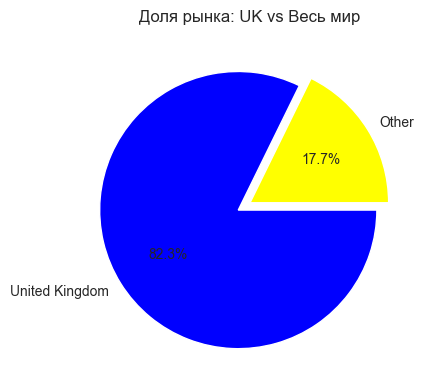

In [103]:
# Создаем укрупненную группу стран: оставляем United Kingdom, остальные размечаем как 'Other'
country_analytics['CountryGroup'] = country_analytics['Country'].map(
    {'United Kingdom': 'United Kingdom'}).fillna('Other')

# Группируем данные по новой категории и считаем общую выручку
servo_df = country_analytics.groupby(
    by=['CountryGroup'], as_index=False)['total_revenue'].sum()

uk_vs_others = servo_df['total_revenue']

# Строим круговую диаграмму соотношения рынка UK и остального мира
plt.figure(figsize=(4.5, 4.5))  # Задаем размер графика
plt.title('Доля рынка: UK vs Весь мир')  # Название графика
labels = servo_df['CountryGroup']  # Название секторов
colors = ['yellow', 'blue'] # Цвета секторов диаграммы
plt.pie(
    uk_vs_others,  # Исходные данные
    labels = labels,
    colors = colors,
    autopct ='%.1f%%', # Корректирует значение после запятой и доб. знак %
    explode = [0, 0.1], # Смещение секторов, в данном случае смещен один сектор на 10%   
)
plt.show()

#### Результаты визуализации:
* **Ключевой инсайт:** Круговая диаграмма подтверждает абсолютное доминирование локального рынка Великобритании (он занимает более 80% в общей доле выручки).
* **Бизнес-решение для моделирования:** Из-за такого сильного дисбаланса поведение зарубежных клиентов может выглядеть как статистический шум для алгоритмов машинного обучения. Эту специфику мы обязательно учтем далее при расчете признаков и интерпретации финальных кластеров.
* **Инженерное решение:** Учитывая подавляющую долю рынка Великобритании, признак `CountryGroup` интегрирован в основной датасет `df_eda` в качестве базового. Это позволит на следующих этапах гибко фильтровать данные и разделять локальные и экспортные паттерны поведения клиентов.

##### Поскольку рынок Великобритании занял почти всю круговую диаграмму и скрыл детали по другим регионам, исключим его из текущего анализа. Построим график для Топ-10 исключительно зарубежных стран по объему выручки. Это позволит детально рассмотреть структуру внешних рынков компании.

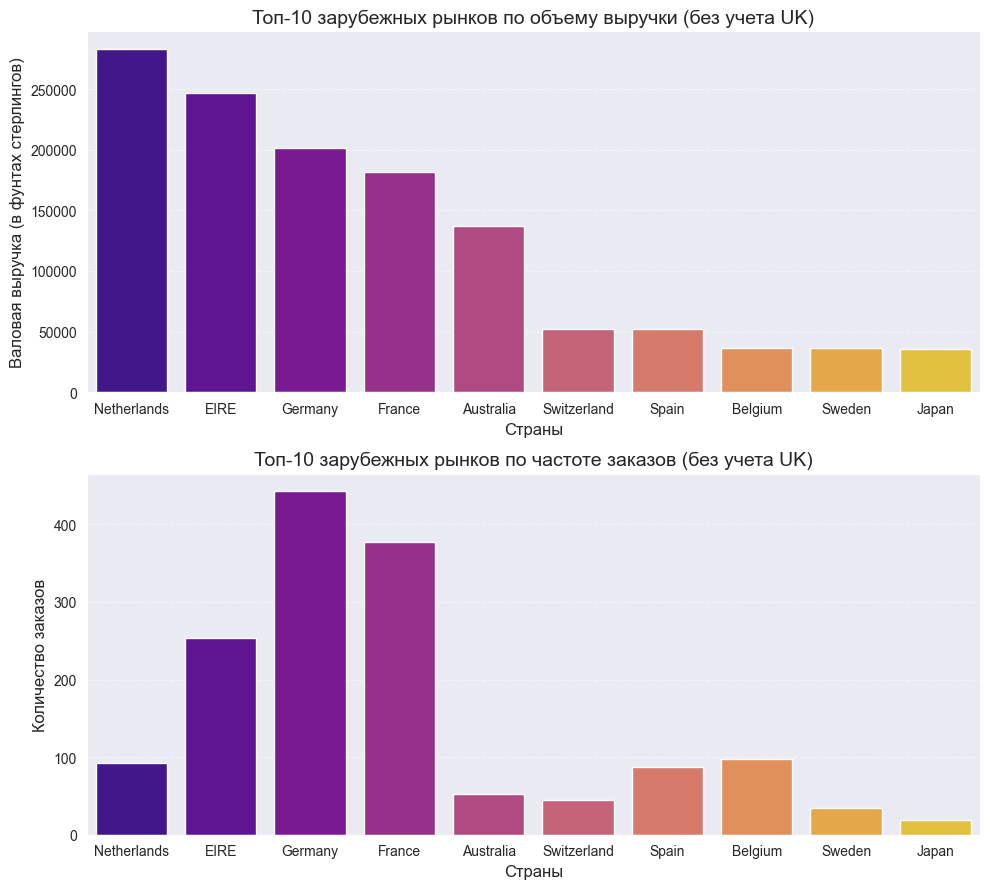

In [104]:
# Отсекаем Великобританию и берем топ-10 зарубежных стран по выручке
top_foreigners = country_analytics[country_analytics['Country']!='United Kingdom'].head(10)

# Задаем размер фигуры
fig, axes = plt.subplots(2, 1, figsize=(10, 9))

sns.barplot(
    data = top_foreigners,  # DataFrame для построения графика
    x='Country',  # Отложим по оси х страны
    y='total_revenue',  # Отложим по оси у валовую выручку
    palette = 'plasma',  # Название палитры
    ax=axes[0] 
)
# Добавляем названия и подписи
axes[0].set_title(
    'Топ-10 зарубежных рынков по объему выручки (без учета UK)', fontsize=14)
axes[0].set_xlabel('Страны', fontsize=12)
axes[0].set_ylabel('Валовая выручка (в фунтах стерлингов)', fontsize=12)
axes[0].grid(axis='y', linestyle='--', alpha=0.5) # Сетка для удобства чтения цифр

sns.barplot(
    data = top_foreigners,  # DataFrame для построения графика
    x='Country',  # Отложим по оси х страны
    y='total_orders',  # Отложим по оси у валовую вырочку
    palette = 'plasma',  # Название палитры
    ax=axes[1] 
)
# Добавляем названия и подписи
axes[1].set_title(
    'Топ-10 зарубежных рынков по частоте заказов (без учета UK)', fontsize=14)
axes[1].set_xlabel('Страны', fontsize=12)
axes[1].set_ylabel('Количество заказов', fontsize=12)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)  # Сетка для удобства чтения цифр

# Отображаем график
plt.tight_layout()
plt.show()


#### Результаты совмещенного анализа зарубежных рынков:

* **Методология сравнения:** Для наглядности анализа порядок стран на нижнем графике жестко зафиксирован по убыванию валовой выручки верхнего графика. Это позволяет напрямую сопоставить финансовую ценность регионов с частотой их заказов.
* **Выявление оптового сегмента (Нидерланды):** Нидерланды (`Netherlands`) уверенно лидируют по объему выручки, но при этом показывают относительно небольшое количество инвойсов. Это явный маркер работы крупных оптовиков, которые заказывают редко, но очень большими партиями.
* **Выявление розничного сегмента (Германия):** В Германии (`Germany`) ситуация зеркальная — страна занимает лишь третье место по деньгам, но лидирует по частоте транзакций с огромным отрывом. Это указывает на доминирование частных клиентов, покупающих товары для личных нужд небольшими чеками.
* **Бизнес-вывод для моделирования:** Данный инсайт доказывает, что сегментировать клиентов по какому-то одному показателю неэффективно. Нам необходима многомерная кластеризация, которая учтет и объемы, и частоту покупок, что полностью подтверждает ценность будущего RFM-анализа.

### 2.2. Анализ сезонности и структуры выручки

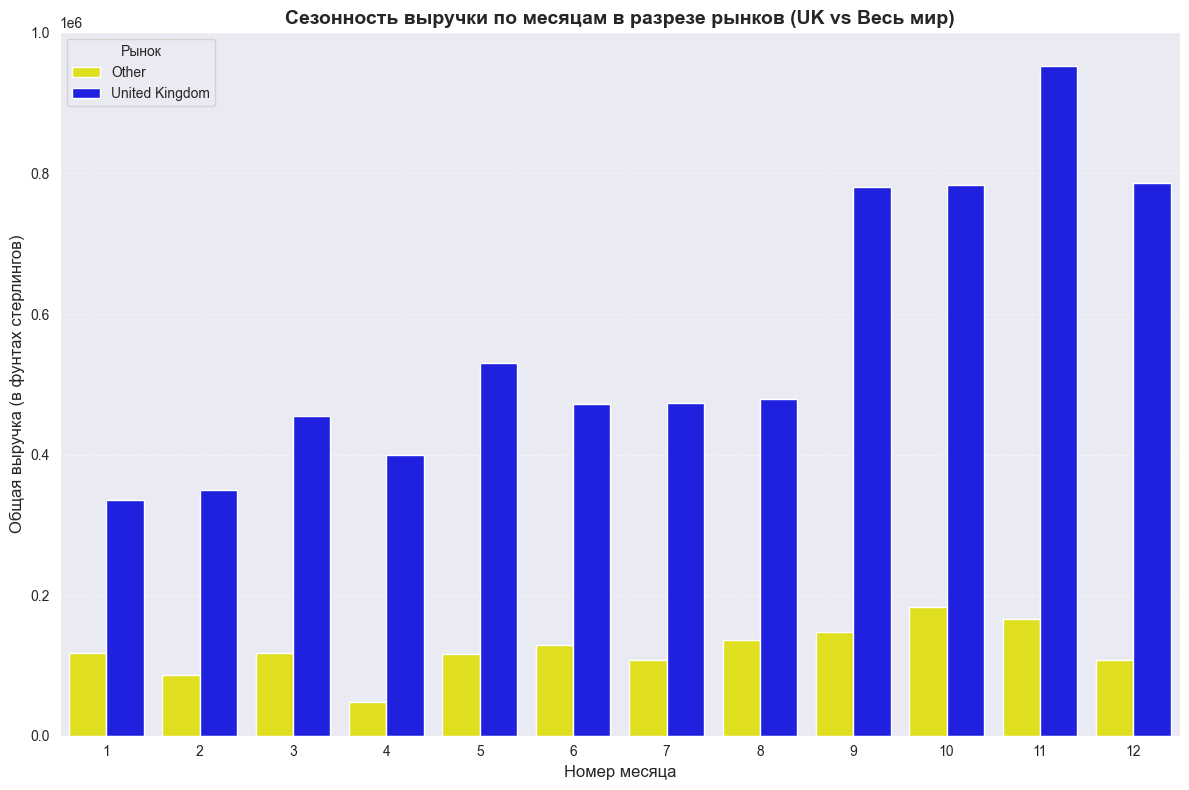

In [105]:
# Извлекаем месяц из даты транзакции
df_eda['MonthSales'] = df_eda['InvoiceDate'].dt.month

# Группируем продажи по месяцам и по группам стран (UK / Other)
monthly_geo_sales = df_eda.groupby(
    ['MonthSales', 'CountryGroup'], as_index=False)['TotalPrice'].sum()

# Настраиваем размер графика
plt.figure(figsize=(12, 8))

# Строим столбчатую диаграмму, где цвета (hue) разделяют UK и Other
sns.barplot(
    data=monthly_geo_sales, 
    x='MonthSales', 
    y='TotalPrice', 
    hue='CountryGroup', 
    palette=['yellow', 'blue'] # Сохраняем цвета: синий для UK, желтый для Other
)
# Добавляем оформление
plt.title(
    'Сезонность выручки по месяцам в разрезе рынков (UK vs Весь мир)', 
    fontsize=14, fontweight='bold'
)
plt.xlabel('Номер месяца', fontsize=12)
plt.ylabel('Общая выручка (в фунтах стерлингов)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(title='Рынок')

plt.tight_layout()
plt.show()

#### Выводы по анализу сезонности:

* **Выраженный пик в конце года:** На графике отчетливо виден резкий рост выручки начиная с сентября, который достигает своего максимума в ноябре. В декабре показатели также остаются на высоком уровне.
* **Синхронность рынков:** Сезонные колебания на домашнем рынке (United Kingdom) и на зарубежных направлениях (Other) аналогичны. Это говорит о том, что факторы, влияющие на поведение клиентов, одинаковы для всех регионов.
* **Бизнес-логика:** Такой всплеск продаж в осенне-зимний период полностью оправдан спецификой магазина (онлайн-ритейлер подарков). Основной доход компании формируется за счет предновогодних и рождественских закупок, которые оптовики и розничные клиенты делают заранее.
* **Основной вывод:** Спрос зависит от сезона.

##### Определим, какие именно зарубежные страны вносят наибольший вклад в общую прибыль компании во время пикового сезона. Для этого отфильтруем транзакции за осенне-зимний период (сентябрь–декабрь) и рассчитаем совокупную сезонную выручку в разрезе иностранных государств.

In [106]:
# Отбираем транзакции только за пиковые осенне-зимние месяцы (сезон повышенного спроса)
seasonal_period = df_eda[df_eda['MonthSales'].isin([9, 10, 11, 12])]

# Исключим Великобританию из списка стран
mask_ukless = seasonal_period['Country'] != 'United Kingdom'

# Считаем сезонную выручку по странам, исключая Великобританию
best_country = seasonal_period[mask_ukless].groupby(
    'Country')['TotalPrice'].sum().sort_values(ascending=False).reset_index()

best_country.head()

,Country,TotalPrice
0,Netherlands,113333.42
1,EIRE,105414.31
2,France,88774.79
3,Germany,87559.04
4,Australia,30390.33


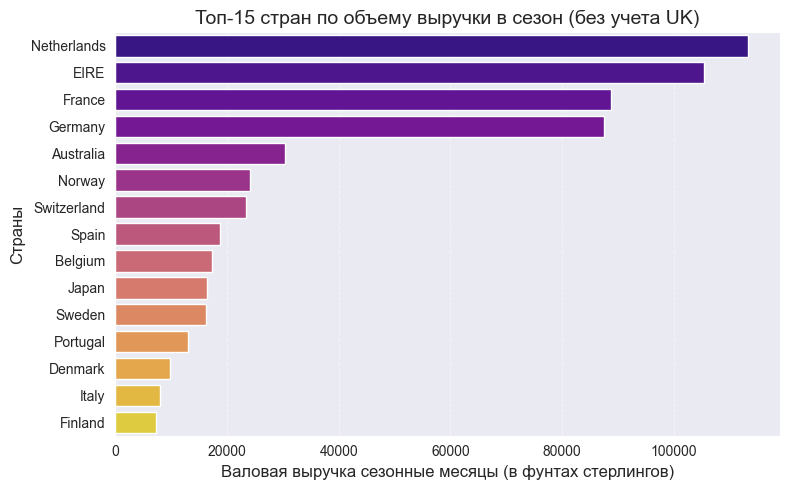

In [107]:
# Задаем размер фигуры
plt.figure(figsize=(8, 5))

sns.barplot(
    data = best_country.head(15),  # DataFrame для построения графика
    x='TotalPrice',  # Отложим по оси х страны
    y='Country',  # Отложим по оси у валовую вырочку
    palette = 'plasma'  # Название палитры  
)
# Добавляем названия и подписи
plt.title('Топ-15 стран по объему выручки в сезон (без учета UK)', fontsize=14)
plt.xlabel('Валовая выручка сезонные месяцы (в фунтах стерлингов)', fontsize=12)
plt.ylabel('Страны', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5) # Легкая сетка для удобства чтения цифр

# Отображаем график
plt.tight_layout()
plt.show()

#### Результаты анализа сезонной выручки:
* **Ключевые драйверы сезонных продаж:** Основными генераторами выручки за пределами Великобритании в пиковый период являются: Нидерланды, Ирландия, Франция и Германия.
* **Бизнес-вывод:** Именно эти страны обеспечивают компании максимальный международный доход в предпраздничные месяцы. Покупатели из этих регионов демонстрируют высокую готовность к крупным сезонным закупкам, что делает их приоритетными целями для предсезонных маркетинговых кампаний.

### 2.3. Исследование внутридневной активности и плотности заказов

Перейдем к анализу микросезонности и изучим, как распределяется поток заказов в течение суток. Для этого проведем двухэтапную агрегацию: сначала посчитаем точное количество уникальных заказов для каждой пары "дата-час", а затем определим среднее число ежедневно поступающих заказов в каждый конкретный час. Это поможет понять пиковые часы нагрузки на платформу.

In [108]:
# Выделяем чистую дату и час совершения транзакции
df_eda['DaySales'] = df_eda['InvoiceDate'].dt.date
df_eda['HourSales'] = df_eda['InvoiceDate'].dt.hour

# Находим количество уникальных заказов на каждый день-час
daily_hourly_order = df_eda.groupby(
    by=['DaySales', 'HourSales'], as_index=False)['InvoiceNo'].nunique()

# Находим среднее количество ежедневных заказов для каждого часа
avg_hourly_orders = daily_hourly_order.groupby(
    by=['HourSales'], as_index=False)['InvoiceNo'].mean()

# Переименовываем колонку для финального графика
avg_hourly_orders.columns = ['HourSales', 'AvgOrders']
avg_hourly_orders['AvgOrders'] = avg_hourly_orders['AvgOrders'].round(2)

# Сортируем данные в колонке 'AvgOrders' от большего к меньшему
avg_hourly_orders = avg_hourly_orders.sort_values(by='AvgOrders', ascending=False)

# Выводим результат
avg_hourly_orders.head()


,HourSales,AvgOrders
6,12,10.18
7,13,8.65
8,14,7.45
5,11,7.40
4,10,7.21


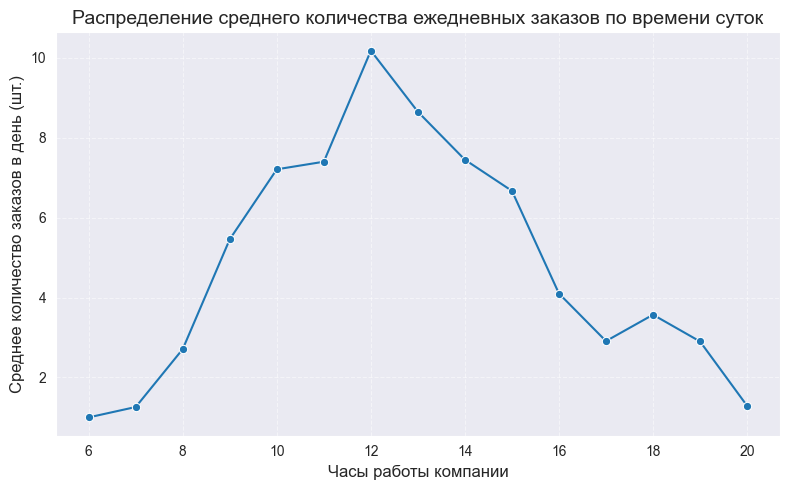

In [109]:
# Настраиваем размер окна графика
plt.figure(figsize=(8, 5))

# Строим линейный график распределения средней активности
sns.lineplot(
    data = avg_hourly_orders,  # DataFrame для построения графика
    x='HourSales',  # Отложим по оси х рабочие часы
    y='AvgOrders',  # Отложим по оси у сред. количество заказов в день
    marker='o',  # Добавляем круглые маркеры на каждый рабочий час
    palette = 'viridis' # Цветовая палитра
)
# Добавляем названия и подписи
plt.title(
    'Распределение среднего количества ежедневных заказов по времени суток', 
    fontsize=14
)
plt.xlabel('Часы работы компании', fontsize=12)
plt.ylabel('Среднее количество заказов в день (шт.)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


#### Результаты анализа внутридневной активности:
* **График работы платформы:** На основе транзакционного лога зафиксировано, что активные операции совершаются в интервале с 6 часов утра до 20 часов вечера. Ночью заказы отсутствуют.
* **Пик покупательской активности:** Максимум ежедневных заказов приходится на период с 10:00 до 15:00 и особенно в обеденное время (с 12:00 до 13:00). 
* **Бизнес-применение инсайта:** Выявленный паттерн критически важен для маркетинга компании. Время пиковой активности — это идеальное окно для запуска email-рассылок, push-уведомлений и таргетированной рекламы, так как в эти часы пользователи находятся на сайте и демонстрируют максимальную готовность к покупке.

#### 💡 Перспективы коммерческого применения модели (Workforce Management):

* **Оптимизация штатного расписания:** Выявленная внутридневная и ежедневная сезонность — это готовый инструмент для оптимизации затрат на персонал (сборщиков заказов, операторов поддержки, курьеров). 
* **Бизнес-логика планирования:** Вместо фиксированных смен «всегда одинаковым составом» данные позволяют гибко масштабировать команду. Например, под пиковые часы (с 12:00 до 14:00) и в самые загруженные дни недели выводится максимальное число сотрудников. В утренние или «спящие» дни выводится минимальная дежурная смена.
* **Финансовый эффект:** Такой подход исключает две главные проблемы ритейла:
  1. *Убытки от простоя:* когда сотрудники «болтаются без дела» в часы низкой активности, а компания зря платит за их рабочее время.
  2. *Выгорание и упущенная прибыль:* когда в пиковые часы команда перегружена, из-за чего падает скорость сборки и клиенты уходят к конкурентам.

### 2.4. Профилирование клиентской базы: Оптовый и Розничный сегменты

Для формирования таргетированных маркетинговых стратегий необходимо разделить клиентскую базу на розничных покупателей и оптовых контрагентов. Чтобы исключить дублирование данных (так как один инвойс содержит множество товарных строк, из-за чего общая сумма чека дублируется), сначала сожмем транзакционный лог до уровня уникальных заказов. 

Построим гистограмму распределения стоимости уникальных инвойсов (`TotalSum`), чтобы эмпирическим путем определить объективную границу раздела сегментов.

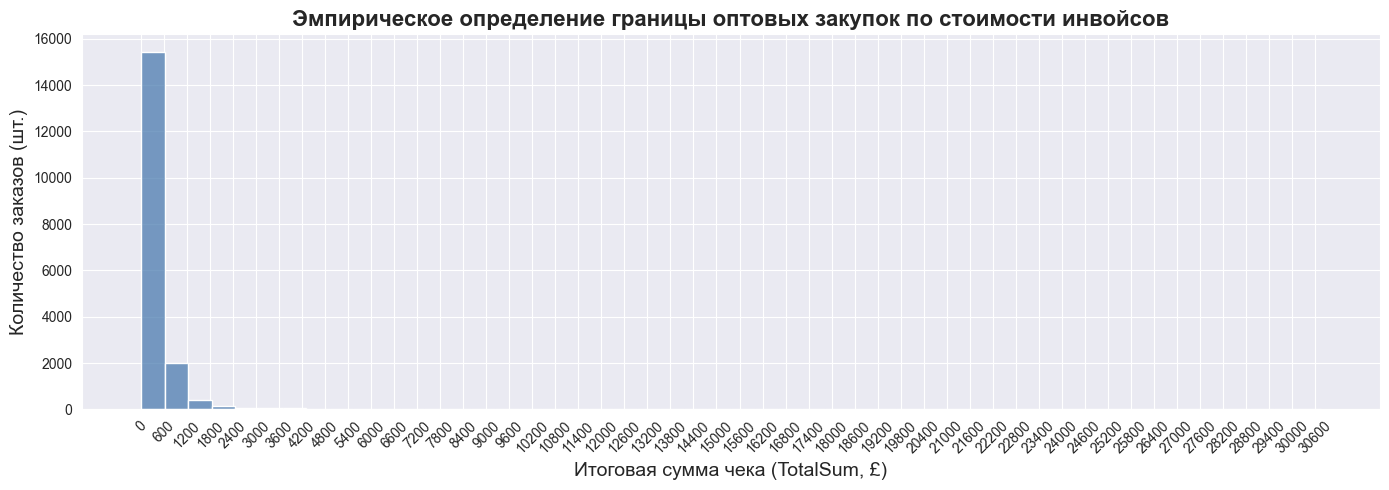

In [110]:
# Сжимаем датасет до уровня уникальных заказов (один заказ — одна строка со стоимостью)
orders_df = df_eda.groupby(['CustomerID', 'InvoiceNo'], as_index=False)['TotalSum'].first()

# Находим максимальный чек для настройки шкал
max_check = df_eda['TotalSum'].max()

# Зададим размер полотна
plt.figure(figsize=(14, 5))

sns.histplot(
    data = orders_df,
    x='TotalSum',
    bins = 50,
    color="#4C7CB0"
)
plt.title(
    'Эмпирическое определение границы оптовых закупок по стоимости инвойсов', 
    fontsize=16, 
    fontweight='bold'
)
plt.xlabel('Итоговая сумма чека (TotalSum, £)', fontsize=14)
plt.ylabel('Количество заказов (шт.)', fontsize=14)
plt.xticks(range(0, int(max_check), 600), rotation=45)
plt.tight_layout()
plt.show()

#### Анализ распределения и обоснование порога:
Визуальный анализ гистограммы показывает, что подавляющее большинство заказов сосредоточено в левой части спектра (до 1200 фунтов стерлингов). После отметки **1200 £** плотность распределения резко падает, и начинается длинный "хвост" единичных сверхкрупных транзакций. 

Таким образом, значение **1200 £** принимается в качестве базовой границы раздела: чеки ниже этого порога относятся к мелкооптовому и розничному сегменту, а чеки равные или выше — к оптовому.

Используя этот критерий, рассчитаем структуру клиентской базы и средние чеки для каждого профиля.

In [111]:
# Находим средний чек для каждого уникального клиента на основе очищенных заказов
client_check = orders_df.groupby(by='CustomerID', as_index=False)['TotalSum'].mean()
client_check.columns = ['CustomerID', 'ClientAvgCheck']

# Категоризируем клиентов по обоснованной границе в 1200 фунтов
client_check['ClientType'] = client_check['ClientAvgCheck'].apply(
    lambda x: 'Wholesale' if x >= 1200 else 'Retail')

# Расчет долей рынка и средних чеков
client_share = client_check['ClientType'].value_counts(normalize = True)*100
type_avg_check = client_check.groupby(by='ClientType')['ClientAvgCheck'].mean()

print(f"Доля оптовых клиентов: {client_share['Wholesale']:.2f}%")
print(f"Доля розничных клиентов: {client_share['Retail']:.2f}%")
print('='*38)
print(f"Средний чек оптового клиента: {type_avg_check['Wholesale']:.2f} £")
print(f"Средний чек розничного клиента: {type_avg_check['Retail']:.2f} £")

Доля оптовых клиентов: 2.59%
Доля розничных клиентов: 97.41%
Средний чек оптового клиента: 2291.56 £
Средний чек розничного клиента: 318.93 £


##### Обогащение основного датасета профилями клиентов:
Для того чтобы использовать информацию о типе контрагента на последующих этапах анализа (включая исследование динамики чека и построение графиков), перенесем созданную разметку в основной массив данных. С помощью метода `.merge()` проведем левое соединение (Left Join) по ключевому признаку `CustomerID`, интегрировав колонку `ClientType` в структуру `df_eda`.

In [112]:
# Оставляем только нужные нам для склейки колонки
client_profile = client_check[['CustomerID', 'ClientType']]

# Объединяем основной датасет df_eda с профилями клиентов по ключевой колонке 'CustomerID'
df_eda = df_eda.merge(client_profile, on='CustomerID', how='left')

In [113]:
# Посмотрим на результат склейки
df_eda.head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,QuantityCanceled,TotalPrice,TotalSum,CountSkuCheck,CountryGroup,MonthSales,DaySales,HourSales,ClientType
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,0.0,15.30,139.12,7,United Kingdom,12,2010-12-01,8,Retail
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,0.0,20.34,139.12,7,United Kingdom,12,2010-12-01,8,Retail
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,0.0,22.00,139.12,7,United Kingdom,12,2010-12-01,8,Retail


##### Сопоставление структуры базы и вклада в выручку:
Проведем перекрестный анализ полученных сегментов. Сопоставим доли розничных и оптовых клиентов, их средние чеки и совокупный вклад каждого сегмента в общую годовую выручку платформы. Это позволит оценить реальную значимость каждой группы для бизнеса.

In [114]:
# Сжимаем данные до уникальных инвойсов, сохраняя метку типа клиента
val_df = df_eda.groupby(by=['InvoiceNo','ClientType'], as_index=False)['TotalSum'].first()

# Расчет абсолютной выручки по каждому коммерческому сегменту
val_retail = val_df[val_df['ClientType'] == 'Retail']['TotalSum'].sum()
val_wholesale = val_df[val_df['ClientType'] == 'Wholesale']['TotalSum'].sum()

# Вывод консолидированных результатов финансовой проверки
print(f"Общая сумма продаж за год: {val_df['TotalSum'].sum():.0f} £")
print(f"Общая сумма продаж за год (Retail): {val_retail:.0f} £")
print(f"Общая сумма продаж за год (Wholesale): {val_wholesale:.0f} £")

Общая сумма продаж за год: 8263654 £
Общая сумма продаж за год (Retail): 6185660 £
Общая сумма продаж за год (Wholesale): 2077994 £


#### Результаты структурного и финансового анализа сегментов:

* **Распределение доходов в абсолютном выражении:** Розничный сегмент (`Retail`) сгенерировал основную часть годового дохода компании — **6 185 660 £** (около 75% от общего объема). На долю оптовых контрагентов (`Wholesale`) пришлось **2 077 994 £** (около 25%).
* **Эффект масштаба розницы:** Несмотря на то, что средний чек розничного клиента (**318.93 £**) почти в 7 раз ниже оптового, за счет гигантского численного превосходства (**97.41%** от всей базы) розничный сегмент выступает главным фундаментом выручки платформы.
* **Специфика оптового сегмента:** Крупные контрагенты составляют всего **2.59%** от общего количества клиентов, но обеспечивают ровно четверть доходов компании (**2 077 994 £**) со стабильно высоким средним чеком заказа в **2 291.56 £**. 
* **Важный бизнес-вывод:** Высокий суммарный доход от розничного сегмента при низком среднем чеке говорит о большой частоте повторных заказов внутри этой группы. Данное наблюдение еще раз доказывает, что простая сегментация по объемам затрат (Monetary) упускает скрытые паттерны активности (Frequency). Это подводит нас к необходимости внедрения полноценной трехмерной RFM-кластеризации.

### 2.5. Косвенный анализ поведенческой активности на основе признака CountSkuCheck
Поскольку прямой анализ временной динамики выручки ограничен отсутствием данных за прошлые периоды (YoY), проведем структурный анализ физического наполнения заказов. Метрика `CountSkuCheck` (количество уникальных товарных позиций в одном инвойсе) позволяет оценить глубину корзины без привязки к колебаниям цен и курсов валют.

Исследуем, как распределяется разнообразие ассортимента внутри сформированных бизнес-сегментов (`Retail` и `Wholesale`). Это необходимо для верификации корректности разделения клиентов и понимания паттернов их закупки.

##### Анализ динамики состава заказов (глубины SKU) по месяцам

In [115]:
# Сжимаем датасет до уникальных чеков, чтобы анализировать параметры именно заказов, 
# а не отдельных строк
invoice_profiles = df_eda.groupby(
    by=['MonthSales','InvoiceNo', 'ClientType'], as_index=False)['CountSkuCheck'].first()

# Рассчитаем агрегированные метрики глубины чека для розницы и опта
sku_analysis = invoice_profiles.groupby(by=['MonthSales', 'ClientType'])['CountSkuCheck'].agg([
    'count',   # Всего заказов
    'mean',    # Среднее количество позиций в чеке
    'median',  # Медианное количество позиций (устойчиво к выбросам)
    'min',     # Минимальное наполнение
    'max'      # Максимальный объем одной корзины
]).reset_index().round(2)
sku_analysis.head()

,MonthSales,ClientType,count,mean,median,min,max
0,1,Retail,934,20.55,16.0,1,155
1,1,Wholesale,40,41.72,31.5,1,169
2,2,Retail,940,19.55,14.0,1,244
3,2,Wholesale,48,25.83,15.0,1,109
4,3,Retail,1249,20.18,15.0,1,159


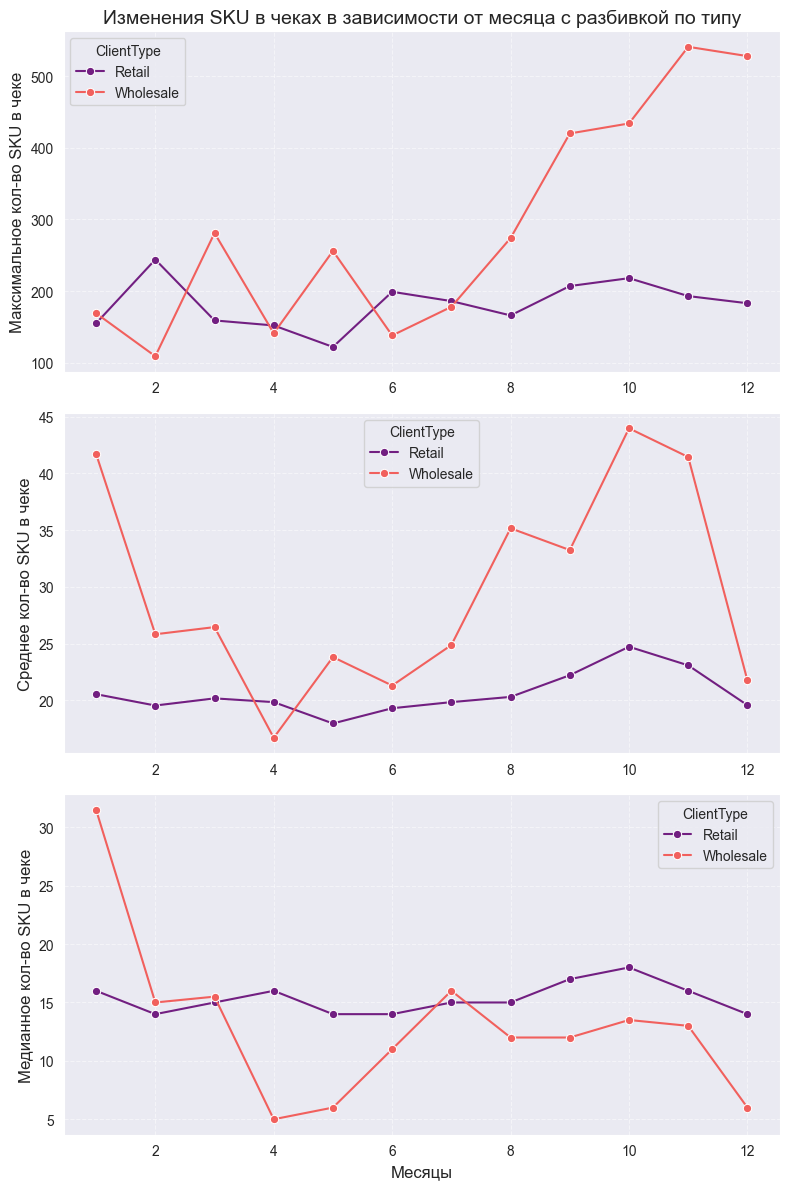

In [116]:
# Инициализируем сетку графиков: 3 строки, 1 столбец. Задаем оптимальный размер.
fig, axes =  plt.subplots(3,1, figsize = (8, 12))

# График максимальной глубины чека (Анализ пиковых оптовых выбросов)
sns.lineplot(
    data=sku_analysis, 
    x='MonthSales',
    y='max',
    hue='ClientType',
    marker='o',
    palette='magma',
    ax=axes[0]
)
# Добавляем названия и подписи
axes[0].set_title(
    'Изменения SKU в чеках в зависимости от месяца с разбивкой по типу', 
    fontsize=14)
axes[0].set_xlabel('')
axes[0].set_ylabel('Максимальное кол-во SKU в чеке', fontsize=12)
# Включаем координатную сетку для удобства считывания трен
axes[0].grid(True, linestyle='--', alpha=0.5) 

# График средней наполненности чека (Анализ общих тенденций объема корзины)
sns.lineplot(
    data=sku_analysis, 
    x='MonthSales',
    y='mean',
    hue='ClientType',
    marker='o',
    palette='magma',
    ax=axes[1]
)
# Добавляем названия и подписи
axes[1].set_xlabel('')
axes[1].set_ylabel('Среднее кол-во SKU в чеке', fontsize=12)
# Включаем координатную сетку для удобства считывания трендов
axes[1].grid(True, linestyle='--', alpha=0.5) 

# График медианной наполненности чека (Анализ устойчивого ядра спроса)
sns.lineplot(
    data=sku_analysis, 
    x='MonthSales',
    y='median',
    hue='ClientType',
    marker='o',
    palette='magma',
    ax=axes[2]
)
# Добавляем названия и подписи
axes[2].set_xlabel('Месяцы', fontsize=12)
axes[2].set_ylabel('Медианное кол-во SKU в чеке', fontsize=12)
# Включаем координатную сетку для удобства считывания трендов
axes[2].grid(True, linestyle='--', alpha=0.5) 

plt.tight_layout()
plt.show()


##### Результаты визуализации поведенческих трендов:
* **Устойчивость розничного спроса (`Retail`):** Розничный сегмент демонстрирует высокую операционную стабильность. Медианная глубина чека на протяжении 12 месяцев стационарна и составляет **~15 уникальных SKU**. Это свидетельствует об устойчивом ядре потребительского поведения и стабильной эффективности рекомендательной системы интерфейса магазина.
* **Сезонность и циклы B2B-закупок (`Wholesale`):** Оптовый сегмент подвержен сильным календарным колебаниям. Зафиксирован глубокий рыночный провал в апреле (месяц минимальной активности), сменяющийся мощным трендом на расширение номенклатурной матрицы, начиная с августа. 
* **Опережающий характер опта:** Пик разнообразия корзины у оптовиков достигается в октябре-ноябре (среднее значение превышает **40-45 SKU**, а максимум уходит за **500 SKU в одном инвойсе**). Это отражает классический паттерн e-commerce: оптовые контрагенты формируют свои склады под рождественские распродажи заблаговременно, завершая закупки к декабрю.
* **Инженерный вывод:** Тот факт, что динамика поведения сегментов принципиально различается (розница — стабильна, опт — высокосезонен), подтверждает архитектурную правильность выделения признака `ClientType`.

## 3. Feature Engineering: Построение и сборка RFM-витрины данных.
**Описание этапа и бизнес-контекст**
Для перехода от транзакционных логов к алгоритмам машинного обучения (Unsupervised Learning) необходимо сформировать репрезентативное пространство признаков, агрегированное на уровне уникальных контрагентов. В качестве методологического фундамента проекта выбран классический и наиболее эффективный в ритейле фреймворк — **RFM-анализ (Recency, Frequency, Monetary)**.

Суть подхода заключается в декомпозиции потребительского поведения каждого клиента по трем ключевым векторам, которые напрямую определяют его ценность для бизнеса и стратегию удержания:
* **`Recency` (Давность)** — количество дней, прошедших с момента совершения крайней транзакции клиента до фиксированной опорной даты. Позволяет оперативно идентифицировать риски оттока (Churn Rate).
* **`Frequency` (Частота)** — совокупное количество уникальных заказов (инвойсов), оформленных клиентом за исследуемый период. Отражает уровень лояльности и плотность взаимодействия с платформой.
* **`Monetary Value` (Монетарная ценность)** — суммарный валовой оборот (выручка), сгенерированный контрагентом. Демонстрирует прямой финансовый вклад в доходы компании.

**Бизнес-контекст и инженерная цель:**
Основная аналитическая задача — перевести непрерывные математические метрики в понятные для коммерческого департамента поведенческие когорты (от «Перспективных новичков» до «Лояльных лидеров» и «Спящих»). Построение многомерных профилей на реальных данных интернет-магазина позволит алгоритмам кластеризации обнаружить скрытые паттерны закупки, минимизируя субъективный человеческий фактор при сегментировании базы.

### 3.1. Расчет RFM векторов

##### Агрегация признаков и расчет вектора Recency:
Для расчета давности активности (`Recency`) математически необходимо определить временную дистанцию между фиксированным моментом мониторинга $t_0$ (10 декабря 2011 года) и моментом совершения крайнего заказа контрагента. 

Применение оператора $\max()$ к множеству транзакций клиента $[t_{i1}, t_{i2}, ..., t_{iM}]$ позволяет изолировать дату его **самого свежего обращения к платформе**. Последующее вычитание этой величины из константы $t_0$ корректно переводит временную метку в непрерывную шкалу дней, прошедших с момента последней покупки покупателя.

In [137]:
# Перед началом построения RFM векторов сделаем копию датасета df_eda
df_rfm = df_eda.copy()

In [138]:
# Задаем фиксированную опорную точку времени (t_0)
starting_point = pd.to_datetime('2011-12-10 00:00:00')

# Агрегируем данные: находим дату последней покупки для каждого CustomerID
customer_recency = df_rfm.groupby(by=['CustomerID'], as_index=False)['InvoiceDate'].max()

# Вычисляем временную дистанцию (Timedelta) до опорной точки в днях тип int.
customer_recency['Recency'] = (starting_point - customer_recency['InvoiceDate']).dt.days

# Удаляем ставшую ненужной колонку с датой
customer_recency = customer_recency.drop(columns=['InvoiceDate'])

# Проверяем результат
customer_recency.head()

,CustomerID,Recency
0,12347,2
1,12348,75
2,12349,18
3,12350,310
4,12352,36


##### Консолидированная агрегация метрик Frequency и Monetary на уровне клиентов
Для формирования оставшихся векторов признакового пространства (`Frequency` и `Monetary`) применим метод оптимизированной групповой агрегации `.agg()` с именованием целевых переменных. Это позволит рассчитать поведенческие метрики за один проход по датасету, минимизируя нагрузку на оперативную память.

**Инженерно-методологический подход:**
1. **`Frequency` (Частота):** Рассчитывается строго через функцию `.nunique()` по признаку `InvoiceNo`. Мы фиксируем именно количество уникальных транзакций (чеков), совершенных контрагентом. Прямой подсчет строк (`.count()`) исказил бы метрику, искусственно завышая активность клиентов с объемными корзинами.
2. **`Monetary` (Монетарная ценность):** Рассчитывается как сумма `.sum()` предварительно очищенного признака `TotalPrice`. Базирование на финальной стоимости позиций гарантирует, что оборот каждого клиента рассчитан корректно — с учетом всех ранее обработанных возвратов и аннулирований.

In [139]:
# Агрегируем транзакционный лог, вычисляя частоту заказов и валовую выручку 
# для каждого контрагента
customer_freq_monet = df_rfm.groupby(by='CustomerID', as_index=False).agg(
    Frequency = ('InvoiceNo', 'nunique'), # Считаем уникальные инвойсы (активность)
    Monetary = ('TotalPrice', 'sum')      # Суммируем чистый финансовый оборот
)
# Проверяем результат
customer_freq_monet.head()

,CustomerID,Frequency,Monetary
0,12347,7,4310.00
1,12348,4,1437.24
2,12349,1,1457.55
3,12350,1,294.40
4,12352,6,1265.41


##### Интеграция признаков в единую аналитическую витрину RFM
На заключительном этапе инженерии признаков объединим рассчитанный ранее вектор давности (`customer_recency`) с таблицей частоты и монетарной ценности (`customer_freq_monet`). 

Для обеспечения целостности данных применим метод `Left Join` по ключевому идентификатору `CustomerID`. Итоговая матрица `rfm_table` станет единым цифровым репрезентатором клиентской базы, готовым к процедурам детекции аномалий и стандартизации.

In [140]:
# Объединяем векторы давности, частоты и объема затрат по ключевому признаку CustomerID
rfm_table = customer_recency.merge(customer_freq_monet, on=['CustomerID'], how='left')

# Выводим консолидированную RFM-матрицу для финального контроля схождения строк
rfm_table.head()

,CustomerID,Recency,Frequency,Monetary
0,12347,2,7,4310.00
1,12348,75,4,1437.24
2,12349,18,1,1457.55
3,12350,310,1,294.40
4,12352,36,6,1265.41


In [121]:
# Переносим ID в индекс, чтобы в колонках остались только три наши метрики
rfm_table_r = rfm_table.set_index('CustomerID')

### 3.2. Визуализация признакового пространства и первичный экспресс-анализ аномалий
**Описание этапа и бизнес-контекст**
Для исследования внутренней геометрии полученных признаков (`Recency`, `Frequency`, `Monetary`) построим одномерные коробчатые диаграммы (**Boxplot / Ящик с усами**). В контексте задач машинного обучения данный тип визуализации является незаменимым инструментом, так как он наглядно отображает ключевые статистические маркеры: медиану, межквартильный размах (IQR) и, главное, наличие экстремальных выбросов (Outliers).

В сфере e-commerce распределение частоты и сумм покупок традиционно характеризуется сильной асимметрией (небольшая группа крупных клиентов генерирует огромную долю транзакций и выручки). Визуализация позволит нам оценить степень этой скошенности и подготовить аналитическую стратегию для этапа очистки данных перед обучением моделей.

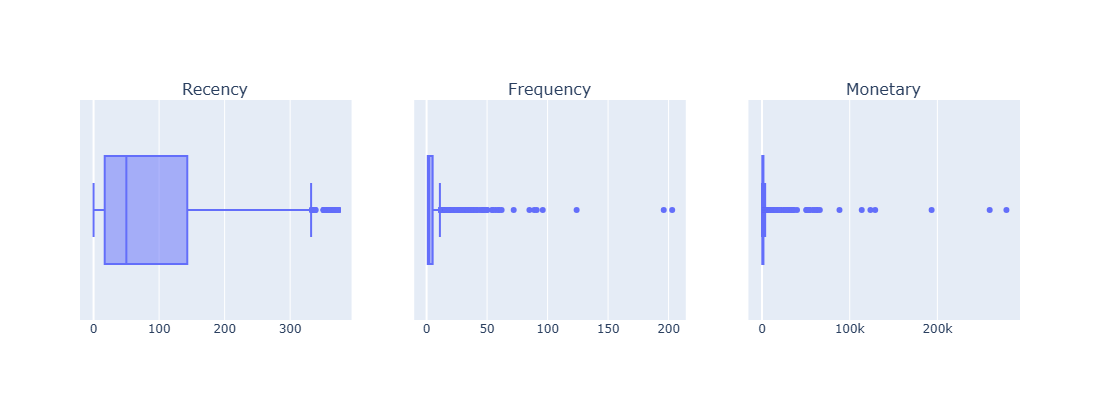

In [141]:
# Создание списка графиков
boxes = [px.box(rfm_table_r, x=column) for column in rfm_table_r.columns]

# Подготовка сетки (шаблона)
fig = make_subplots(
    rows=1, cols=3, 
    subplot_titles=("Recency","Frequency", "Monetary")
)
# Перенос графиков на общую сетку
for i, box in enumerate(boxes):
    fig.add_trace(boxes[i]['data'][0], row=1, col=i+1)

fig.update_layout(
    showlegend=False,  # Отключаем избыточную легенду
    width=1100,        # Увеличиваем ширину, чтобы раздвинуть графики по оси X
    height=400         # Задаем оптимальную высоту
) 
fig.show(renderer='png')  # Запрет интерактивности (статичный рендер для GitHub)
# fig.show()

#### Результаты визуального анализа распределений и выводы:
* **Метрика Recency (Давность):** Демонстрирует наиболее распределенную структуру. Основная масса клиентов сосредоточена в интервале от 0 до 150 дней с момента последней покупки. Правая граница усов доходит до ~330 дней, а немногочисленные точки за ней отражают естественную группу клиентов, совершивших разовые покупки в начале исследуемого периода и перешедших в фазу «спящих». Данный признак стабилен и не генерирует критических аномалий.
* **Метрики Frequency (Частота) и Monetary (Монетарная ценность):** Обладают экстремально скошенным распределением («тяжелые хвосты»). Мы наблюдаем группу ультра-активных клиентов с объемом заказов более 100 единиц и совокупными годовыми затратами, превышающими 100 000–190 000 £. 

#### Почему эти выбросы критичны для моделирования (Риски):
Базовый алгоритм кластеризации — **K-Means** — крайне чувствителен к масштабу и аномалиям, поскольку его целевая функция минимизирует среднеквадратичное расстояние до центроидов. Наличие клиентов-гигантов (крупных B2B-дистрибьюторов) приведет к тому, что алгоритм будет вынужден «растягивать» кластеры в сторону этих единичных сверхвысоких значений. В результате вся основная розничная масса клиентов сожмется в один нечитаемый конгломерат, а математическое качество сегментации деградирует.

### 3.3. Очистка данных от выбросов.
Для сохранения устойчивости модели необходимо произвести фильтрацию экстремальных выбросов по признакам `Frequency` и `Monetary`. Чтобы соблюсти баланс между математической чистотой выборки и сохранением репрезентативности базы, ограничим верхний порог **квантилем уровня 0.95 (95-й перцентиль)**. 

Этот подход позволит отсечь 5% наиболее аномальных контрагентов, которые формируют искажающий шум, и сфокусировать модель на качественном разделении ключевых коммерческих когорт (розницы и стабильного среднего опта).

In [142]:
def get_quantile_bounds(data, feature, low_q=0.0, high_q=0.95):
    """
    Универсальная функция для расчета границ и фильтрации данных по квантилям.
    
    Выделяет данные, не попавшие в заданный интервал перцентилей, и очищает 
    датасет от этих экстремальных значений.

    Args:
        data (pd.DataFrame): Исследуемый датасет.
        feature (str): Наименование признака (колонки) для фильтрации.
        low_q (float, optional): Нижняя граница квантиля. По умолчанию 0.0.
        high_q (float, optional): Верхняя граница квантиля. По умолчанию 0.95
        
    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: Кортеж из двух датафреймов:
            - Первый: датасет со значениями вне указанных границ (аномалии/выбросы).
            - Второй: очищенный датасет со значениями внутри границ.
    """
    # Определяем нижнюю и верхнюю границы фильтрации
    lower_bound = data[feature].quantile(low_q)
    upper_bound = data[feature].quantile(high_q)
    
    # Изолируем аномалии и чистые данные с помощью векторных масок
    outliers = data[(data[feature] < lower_bound) | (data[feature] > upper_bound)]
    cleaned = data[(data[feature] >= lower_bound) & (data[feature] <= upper_bound)]
    
    return outliers, cleaned

In [143]:
# Фильтрация выбросов по признаку Frequency (Частота заказов)
outliers_freq, rfm_cleaned = get_quantile_bounds(
    rfm_table_r, 'Frequency', low_q=0.0, high_q=0.95)
print(f"Число выбросов для признака Frequency: {outliers_freq.shape[0]}")

# Сквозная фильтрация по признаку Monetary (Монетарная ценность)
# Передаем на вход уже частично очищенный датасет rfm_cleaned
outliers_monet, rfm_final_cleaned = get_quantile_bounds(
    rfm_cleaned, 'Monetary', low_q=0.0, high_q=0.95)
print(f"Число выбросов для признака Monetary: {outliers_monet.shape[0]}")

print('='*43)
print(f'Результирующее число записей в чистой выборке: {rfm_final_cleaned.shape[0]}')

Число выбросов для признака Frequency: 205
Число выбросов для признака Monetary: 206
Результирующее число записей в чистой выборке: 3913


#### Результаты многомерной фильтрации и санитизации признаков:
* **Эффективность сквозного пайплайна:** В результате последовательного отсечения экстремальных значений по верхнему квантилю $0.95$ были успешно изолированы и удалены скрытые аномалии. На этапе анализа `Frequency` исключено **205 профилей**, а последующая фильтрация по вектору `Monetary` выявила еще **206 скрытых выбросов**.
* **Сохранение репрезентативности выборки:** Финальный объем очищенного массива данных составляет **3 913 наблюдений**. Мы удержали около 90% от исходной клиентской базы, полностью ликвидировав при этом аномальный «тяжелый хвост» распределения (крупных B2B-дистрибьюторов со сверхвысокими чеками и частотой закупок).
* **Бизнес-обоснование:** Сфокусировав признаковое пространство на диапазоне от 0-го до 95-го перцентиля, мы очистили данные от шума оптовиков-гигантов. Теперь выборка представляет собой монолитный массив розничных и средне-оптовых клиентов, что позволит алгоритму K-Means построить устойчивые, интерпретируемые и коммерчески применимые маркетинговые сегменты.

**Текущий статус:** Пайплайн предобработки и Feature Engineering полностью завершен. Набор данных `rfm_final_cleaned` агрегирован, очищен и валидирован. Проект готов к переходу к следующему макро-этапу — масштабированию признаков (Scaling) и построению моделей кластеризации.

## 4. Машинное обучение, валидация алгоритмов и профилирование кластеров
### 4.1. Проектирование пайплайна предобработки и снижение размерности (PCA)
**Описание этапа и бизнес-контекст**
Для построения устойчивых и интерпретируемых маркетинговых сегментов применим методы ненаставнического машинного обучения (Unsupervised Learning). На входе мы имеем три непрерывных признака (`Recency`, `Frequency`, `Monetary`), обладающих разным масштабом и физическим смыслом, что критично для что критично для алгоритмов, основанных на расчете расстояний.

**Инженерный подход и архитектура решения:**
1. **Инкапсуляция в Pipeline:** Для предотвращения утечки данных (Data Leakage) и обеспечения воспроизводимости кода все этапы трансформации данных объединяются в сквозной конвейер `scikit-learn Pipeline`.
2. **Стандартизация (`StandardScaler`):** Центрирует данные и приводит их к единой дисперсии (z-score). Это обязательное требование для корректной работы алгоритмов, вычисляющих евклидовы расстояния.
3. **Снижение размерности (`PCA`):** Метод главных компонент проецирует трехмерное пространство RFM на двумерную плоскость (*n_components=2*). Это решает задачу декорреляции признаков, ускоряет сходимость моделей и позволяет построить наглядные интерактивные графики распределения будущих кластеров для бизнеса.

In [144]:
# Импортируем необходимые библиотеки
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Строим конвейер предобработки данных
preproc_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42))
])
# Применяем пайплайн к очищенной витрине RFM
X_transformed = preproc_pipeline.fit_transform(rfm_final_cleaned)

print(f"Форма матрицы признаков после PCA: {X_transformed.shape}")

Форма матрицы признаков после PCA: (3913, 2)


### 4.2. Валидация алгоритмов и подбор оптимального числа сегментов
Для честного и всестороннего сравнения мы выберем три принципиально разные математические модели кластеризации:
1. **K-Means (Метод k-средних):** Расстояние до центроидов.
2. **Agglomerative Clustering (Иерархическая кластеризация):** Восходящий агломеративный подход на основе дисперсионного критерия Уорда.
3. **Gaussian Mixture Models (GMM / EM-алгоритм):** Вероятностный подход на основе смеси нормальных распределений.

**Критерий оптимизации:**
Поиск оптимального количества бизнес-когорт проведем методом перебора в тестируемом интервале $k \in [3, 10]$. В качестве ключевой метрики валидации используется **коэффициент силуэта (Silhouette Score)**. Он оценивает плотность кластеров и расстояние между ними, позволяя выбрать алгоритм с наиболее четкими и математически обоснованными границами разделения клиентов.

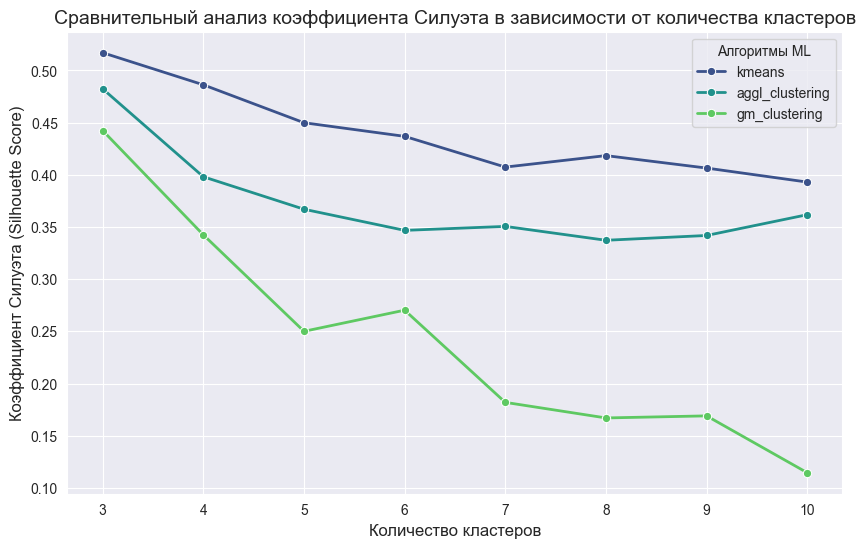

In [145]:
# Импортируем необходимые библиотеки
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

# Динамическая инициализация конфигураций моделей через lambda-функции
models_func = {
    'kmeans': lambda k: KMeans(
        n_clusters=k, init="k-means++", n_init=10, random_state=42),
    'aggl_clustering': lambda k: AgglomerativeClustering(
        n_clusters=cluster_num, linkage='ward'),
    'gm_clustering': lambda k: GaussianMixture(
        n_components=cluster_num, random_state=42) 
}  
# Матрица для логирования результатов экспериментов
results = []

# Запускаем цикл перебора моделей
for name, func in models_func.items():
    
    # Временные списки для сбора метрик текущей модели
    cluster_counts = []
    silhouette_scores = []
    
    # Создадим пустой словарь, ключами будут инерция и количество кластеров
    silhouette_res = {"silhouette": [], "clusters_count": []}
    
    # Итерационный перебор целевого диапазона количества кластеров
    for cluster_num in range(3, 11):
        
        # Инициализируем модель, передавая текущий шаг cluster_num в lambda-функцию
        model = func(cluster_num)
        
        # Генерация векторов меток кластеризации 
        labels = model.fit_predict(X_transformed)
        
        # Расчет метрики качества разделения (Коэффициент силуэта)
        score = silhouette_score(X_transformed, labels)
        
        cluster_counts.append(cluster_num)
        silhouette_scores.append(score)
          
    # Формируем структурированный датафрейм для текущей модели
    model_results_df = pd.DataFrame({
        'clusters_count': cluster_counts,
        'silhouette': silhouette_scores,
        'model': name
    })   

    results.append(model_results_df)
    
# Объединение всех результатов в единую  матрицу
final_scores_df = pd.concat(results, ignore_index=True)
    
# =========================================================================
# СВОДНАЯ ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ ML-ЭКСПЕРИМЕНТА
# =========================================================================
    
# Визуализируем зависимость Силуэта от количества кластеров
plt.figure(figsize = (10, 6))
# Установим стиль для визуализиции
sns.set_style("darkgrid")

# Строим мульти-линейный график, где параметр hue разделит модели по цветам
sns.lineplot(
    data=final_scores_df,
    x="clusters_count",  # По оси х отложим количество кластеров
    y="silhouette",      # По оси у отложим коэф. Силуэта
    hue="model",         # Группировка (разделение) данных по моделям с помощью цвета
    marker= "o",         # Форма точек на графике — круглые маркеры
    palette='viridis',   # Выбор цветовой палитры
    linewidth=2          # Толщина линии графика
)
# Оформление метаданных визуализации
plt.title(
    'Сравнительный анализ коэффициента Силуэта в зависимости от количества кластеров', 
    fontsize=14)
plt.xlabel('Количество кластеров', fontsize=12)
plt.ylabel('Коэффициент Силуэта (Silhouette Score)', fontsize=12)
plt.legend(title='Алгоритмы ML', loc='upper right')
plt.xticks(range(3, 11)) # Явно задаем шаг сетки по оси X от 3 до 10

plt.show()

##### Результаты валидации по коэффициенту Силуэта:
* **Абсолютный математический пик:** Максимальное значение коэффициента силуэта ($\approx 0.51$) для алгоритма `K-Means` достигается при разбиении на **$k=3$** кластера.
* **Бизнес-контекст ($k=4$):** При переходе к 4 кластерам метрика снижается незначительно (до $\approx 0.48$), однако теоретическая модель e-commerce предполагает, что три коммерческие когорты или одна из них могут быть избыточно укрупненными.

**Инженерное решение:** 
Для принятия окончательного архитектурного решения проведем параллельное моделирование и пространственный анализ геометрии распределения объектов в 3D-пространстве для обеих конфигураций ($k=3$ и $k=4$).

### 4.3. Сравнительный анализ и финальная сборка ML-конвейера
**Описание этапа и бизнес-контекст**
Для принятия окончательного решения проведем сравнение моделей с разным количеством групп ($k=3$ и $k=4$). Нам важно оценить не только сухие математические метрики, но и реальное распределение объемов клиентов, а также физические границы разделения в пространстве, чтобы выбрать коммерчески наиболее эффективную конфигурацию.

**Инженерный подход и последовательность действий:**
1. **Контроль распределения объемов:** Расчет количества клиентов, попадающих в каждый кластер для обоих сценариев, с целью исключения вырожденных микро-групп.
2. **Пространственная 3D-визуализация:** Построение трехмерных диаграмм рассеяния (3D Scatter Plot) для наглядной оценки геометрии и плотности границ разделения объектов.
3. **Развертывание итогового пайплайна:** Объединение стандартизации, PCA и утвержденной модели `K-Means` в финальный монолитный конвейер `total_pipeline` для автоматического инференса.

In [146]:
# Инициализируем модель кластеризации KMeans для 3 кластеров
final_kmeans_3 = KMeans(n_clusters=3, init='k-means++', n_init=10, random_state=42)

# Обучаем модель и генерируем метки сегментов для очищенной выборки
final_labels_3 = final_kmeans_3.fit_predict(X_transformed)

# Создаем финальную витрину сегментации, добавляя метки обратно к показателям клиентов
rfm_segmented = rfm_final_cleaned.copy()
rfm_segmented['Cluster_3'] = final_labels_3

# Проверим схождение: выведем распределение объемов полученных кластеров
print("Распределение клиентов по полученным кластерам:")
print(rfm_segmented['Cluster_3'].value_counts())

Распределение клиентов по полученным кластерам:
Cluster_3
0    2111
1     990
2     812
Name: count, dtype: int64


In [147]:
# Инициализируем модель кластеризации KMeans для 4 кластеров
final_kmeans_4 = KMeans(n_clusters=4, init='k-means++', n_init=10, random_state=42)

# Обучаем модель и генерируем метки сегментов для очищенной выборки
final_labels_4 = final_kmeans_4.fit_predict(X_transformed)

# Создаем финальную витрину сегментации, добавляя метки обратно к показателям клиентов
rfm_segmented['Cluster_4'] = final_labels_4

# Проверим схождение: выведем распределение объемов полученных кластеров
print("Распределение клиентов по полученным кластерам:")
print(rfm_segmented['Cluster_4'].value_counts())

Распределение клиентов по полученным кластерам:
Cluster_4
1    1623
2     960
0     911
3     419
Name: count, dtype: int64


#### Результаты контроля распределения объемов:
* **Конфигурация $k=3$:** Демонстрирует классическое ритейл-распределение с явным доминированием базовой группы (Кластер 0 включает 2 111 контрагентов, что составляет более 54% всей базы).
* **Конфигурация $k=4$:** Показывает более глубокую и сбалансированную структуру. Монолитное розничное облако успешно разделяется на два слоя: активный ритейл (1 623 клиента) и сегмент неактивных - "спящих" (960 клиентов). Одновременно с этим алгоритм четко изолирует коммерческое ядро компании, разделяя его на перспективный средний опт (911 клиентов) и компактную VIP-когорту крупных оптовиков (419 клиентов). 

**Инженерная задача:** Ни один из сценариев не содержит критически «вырожденных» микро-кластеров, что подтверждает математическую стабильность обеих моделей. Перейдем к их геометрическому анализу для оценки физических границ разделения.

In [148]:
# Фиксируем средние показатели для 4 кластеров
grouped_rfm = rfm_segmented.groupby('Cluster_4')[['Recency', 'Frequency', 'Monetary']].mean()

# Выводим текстовую таблицу на экран для контроля цифр
print("Финальные средние значения RFM-метрик по 4 кластерам:")
print(grouped_rfm.round(2))

Финальные средние значения RFM-метрик по 4 кластерам:
           Recency  Frequency  Monetary
Cluster_4                              
0            45.06       4.18   1360.26
1            55.54       1.70    437.83
2           257.14       1.38    377.86
3            30.04       7.66   2602.54


#### Пространственная визуализация полученных кластеров в 3D

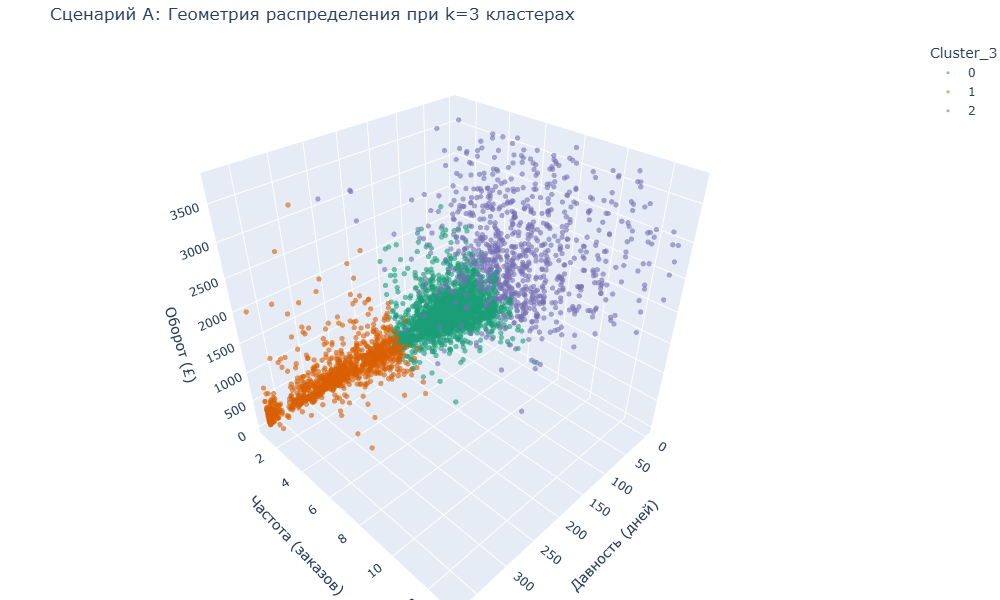

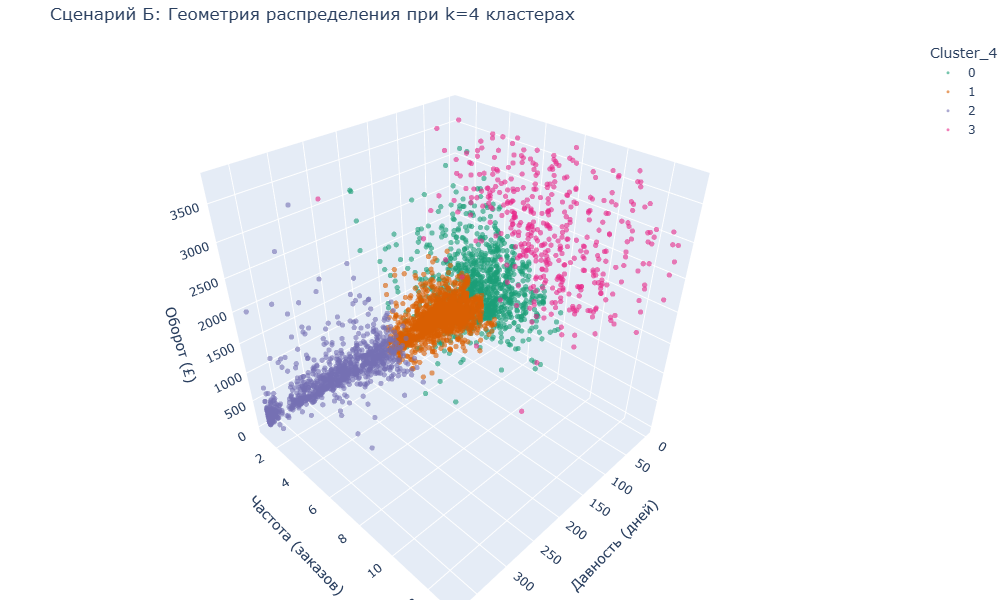

In [ ]:
# -------------------------------------------------------------------------
# Сценарий А: Визуализация 3 кластеров (Математический подход)
# -------------------------------------------------------------------------

# Подготовка данных
# Сортируем для корректного отображения легенды и приводим к str, 
# чтобы Plotly воспринимал кластеры как дискретные категории (а не числа)
rfm_segmented_sorted = rfm_segmented.sort_values(by='Cluster_3')
rfm_segmented_sorted['Cluster_3'] = rfm_segmented_sorted['Cluster_3'].astype(str)

# Построение трехмерного графика рассеяния
fig_3d_k3 = px.scatter_3d(
    rfm_segmented_sorted, 
    x='Recency', y='Frequency', z='Monetary', 
    color='Cluster_3',  # Разделение точек по цветам в зависимости от кластера
    title='Сценарий А: Геометрия распределения при k=3 кластерах',
    labels={        # Переименование осей для понятного отображения на графике
        'Recency': 'Давность (дней)', 
        'Frequency': 'Частота (заказов)', 
        'Monetary': 'Оборот (£)'
    },
    opacity=0.6,  # Полупрозрачность точек для уменьшения визуального наложения
    color_discrete_sequence=px.colors.qualitative.Dark2  # Палитра цветов
)
# Настройка стиля точек (уменьшаем размер, чтобы избежать перегруженности графика)
fig_3d_k3.update_traces(marker=dict(size=3))

# Настройка размеров холста, отступов и включение легенды
fig_3d_k3.update_layout(
    width=1000, height=600, 
    margin=dict(l=0, r=0, b=0, t=40), 
    showlegend=True)

# Экспорт интерактивной веб-версии для портфолио
fig.write_html('data/scatter_3d_3_cluster.html')

fig_3d_k3.show(renderer='png') # Запрет интерактивности (статичный рендер для GitHub)
# fig_3d_k3.show() 

# -------------------------------------------------------------------------
# Сценарий Б: Визуализация 4 кластеров (Бизнес-ориентированный подход)
# -------------------------------------------------------------------------

# Подготовка данных
# Аналогично первому сценарию группируем данные по разметке из 4 кластеров
rfm_segmented_sorted = rfm_segmented.sort_values(by='Cluster_4')
rfm_segmented_sorted['Cluster_4'] = rfm_segmented_sorted['Cluster_4'].astype(str)

# Построение графика для 4 кластеров
fig_3d_k4 = px.scatter_3d(
    rfm_segmented_sorted, x='Recency', y='Frequency', z='Monetary', 
    color='Cluster_4',
    title='Сценарий Б: Геометрия распределения при k=4 кластерах',
    labels={
        'Recency': 'Давность (дней)', 
        'Frequency': 'Частота (заказов)', 
        'Monetary': 'Оборот (£)'
    },
    opacity=0.6, 
    color_discrete_sequence=px.colors.qualitative.Dark2
)
# Оптимизация отображения точек и геометрии холста
fig_3d_k4.update_traces(marker=dict(size=3))
fig_3d_k4.update_layout(
    width=1000, height=600, 
    margin=dict(l=0, r=0, b=0, t=40), 
    showlegend=True)

# Экспорт интерактивной веб-версии для портфолио
fig.write_html('data/scatter_3d_4_cluster.html')

# Отрисовка финального графика
fig_3d_k4.show(renderer='png') # Запрет интерактивности (статичный рендер для GitHub)
# fig_3d_k4.show() 

#### Аналитическое заключение по выбору количества сегментов:
Сопоставление трехмерных пространств наглядно доказывает преимущество **Сценария Б (4 кластера)**:

1. **Проблема деградации при $k=3$:** При разделении на 3 группы модель совершает обобщение. Огромный массив клиентов у основания осей склеивается в единый монолитный кластер. Внутри него оказываются абсолютно разные люди: и «живые» розничные покупатели, и те, кто давно ушел в отток. Совместное управление такой группой для маркетинга неэффективно.
2. **Преимущество дифференциации при $k=4$:** Переход к 4 кластерам позволяет ювелирно расщепить базовое розничное «облако». Модель четко разделяет параметры **«Давность»** и **«Оборот»** на две независимые части:
   * Выделяется плотный узел активной, «свежей» розницы (покупают часто, заходили недавно).
   * Полностью изолируется вытянутый шлейф клиентов, которые имеют высокий накопленный оборот и частоту, но ушли далеко по оси `Recency` (не возвращались более 250–300 дней).

**Итог:** Снижение коэффициента силуэта с $0.51$ до $0.48$ полностью компенсируется большей бизнес-ценностью выделения группы скрытого оттока. Финальным инженерным решением утверждается **конфигурация из 4 кластеров**. Весь дальнейший анализ, построение профилей и расчеты проводятся строго для $k=4$.

#### Развертывание и обучение финального производственного ML-конвейера
На основе проведенного пространственного и бизнес-анализа объединим все этапы трансформации данных и утвержденную модель `K-Means` с конфигурацией из 4 кластеров в единый сквозной конвейер `total_pipeline`. 

Инкапсуляция стандартизации, метода главных компонент (PCA) и финального кластеризатора в один объект гарантирует стопроцентную воспроизводимость результатов, исключает риски смещения данных при инференсе и подготавливает архитектуру модели к экспорту и сохранению для последующей бесшовной интеграции с CRM-системой компании.

In [150]:
# Импортируем необходимые библиотеки
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

# Сборка финального монолитного пайплайна машинного обучения на 4 кластера
total_pipeline = Pipeline([
    ('scaler', StandardScaler()),                  # Шаг 1: Стандартизация Z-score
    ('pca', PCA(n_components=2, random_state=42)), # Шаг 2: Снижение размерности
    ('kmeans', KMeans(
        n_clusters=4, 
        init='k-means++', 
        n_init=10, 
        random_state=42)) # Шаг 3: Кластеризатор на 4 группы
])

# Обучаем весь конвейер и генерируем финальные метки сегментов для чистой выборки
final_labels = total_pipeline.fit_predict(rfm_final_cleaned)

# Создаем итоговую бизнес-витрину и записываем полученные метки кластеров
rfm_segmented = rfm_final_cleaned.copy()
rfm_segmented['Cluster'] = final_labels

# Проверяем успешность разметки и готовность данных к визуализации
print(f"Производственный пайплайн успешно обучен.")
print(f"Все контрагенты распределены по {total_pipeline.named_steps['kmeans'].n_clusters} коммерческим кластерам.")

Производственный пайплайн успешно обучен.
Все контрагенты распределены по 4 коммерческим кластерам.


### 4.4. Многомерное профилирование кластеров на основе лепестковых диаграмм (Radar Chart)
Для качественной интерпретации 4 выбранных сегментов построим лепестковую диаграмму. Она нормализует средние значения признаков в шкалу $[0..1]$, позволяя наглядно оценить поведенческий вектор каждого кластера.

In [151]:
# Фиксируем средние показатели для 4 кластеров
grouped_rfm = rfm_segmented.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

# Выводим текстовую таблицу на экран для контроля цифр
print("Финальные средние значения RFM-метрик по 4 кластерам:")
print(grouped_rfm.round(2))

Финальные средние значения RFM-метрик по 4 кластерам:
         Recency  Frequency  Monetary
Cluster                              
0          45.06       4.18   1360.26
1          55.54       1.70    437.83
2         257.14       1.38    377.86
3          30.04       7.66   2602.54


#### Результаты многомерного профилирования кластеров (Интерпретация 4 бизнес-сегментов):

*   **Cluster 1 — «Стабильный розничный ритейл» (1 1623 клиента):** Самый массовый сегмент базы. Клиенты покупают относительно недавно (средняя давность **~55 дней**), но редко (частота **1.70**) и на небольшие чеки (оборот **437.83 £**). Это классические розничные покупатели. **Стратегия маркетинга:** Увеличение частоты покупок и среднего чека через персонализированные рекомендации (Cross-sell/Up-sell) и триггерные рассылки.
*   **Cluster 2 — «Зона глубокого оттока / Потерянная розница» (960 клиентов):** Мёртвая зона. Средняя давность отсутствия активности составляет критические **257 дней** (более 8.5 месяцев). При этом показатели частоты (**1.38**) и объема затрат (**377.86 £**) минимальны. **Стратегия маркетинга:** Сегмент экономически нецелесообразно заливать дорогим маркетингом. Допустимы разовые реактивационные кампании по «реанимации» (например, отправка промокода на скидку к празднику).
*   **Cluster 0 — «Перспективный средний опт» (911 клиентов):** Клиенты с высокой активностью. Заходили недавно (**~45 дней назад**), покупают часто (**4.18 заказов** за год) и приносят солидный оборот в **1 360.26 £**. Это сильные B2B-контрагенты и серийные розничные покупатели. **Стратегия маркетинга:** Перевод в категорию VIP, стимулирование объемов закупок, превентивное удержание.
*   **Cluster 3 — «VIP-лидеры / Крупный опт» (419 клиентов):** Самый малочисленный, но критически важный и маржинальный сегмент бизнеса. Имеют минимальную давность заказа (**всего 30 дней**), феноменальную частоту покупок (**7.66 инвойсов** за год) и лавинообразный оборот — в среднем **2 602.54 £** на одного контрагента. **Стратегия маркетинга:** Эксклюзивные программы лояльности, выделенный B2B-менеджмент, индивидуальное ценообразование.

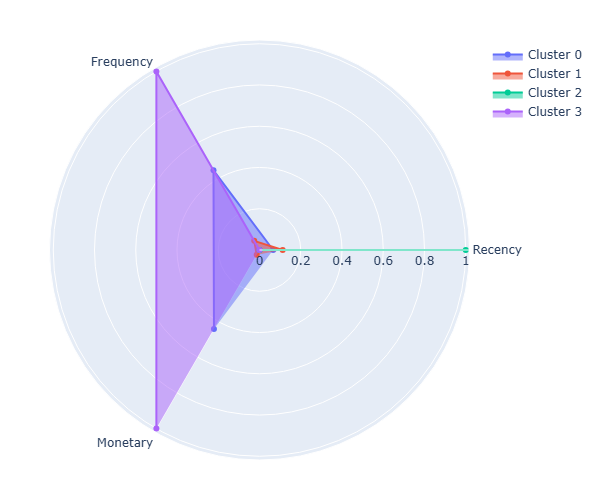

In [152]:
# Импортируем необходимый метод нормализации
from sklearn.preprocessing import MinMaxScaler

def plot_cluster_profile(grouped_data, n_clusters):
    """
    Функция обеспечивает визуализацию многомерных профилей кластеров в виде 
    полярной диаграммы (Radar Chart). Нормализует признаки в шкалу [0..1] 
    для корректного сопоставления.
    
    Args:
        grouped_data (pd.DataFrame): Таблица, сгруппированная по номерам кластеров 
                                     с агрегированными характеристиками объектов.
        n_clusters (int): Количество кластеров.
        
    Returns:
        None: Функция ничего не возвращает, результат визуализируется на экране.
        
    Side Effects:
        - Сохраняет интерактивную карту в файл 'rfm_radar_profiles.html'.
        - Выводит статичное изображение графика (PNG) в текущем интерфейсе.
    """
    # Локальная нормализация для приведения разномасштабных RFM-метрик к 
    # сопоставимому базису
    scaler = MinMaxScaler()
    grouped_data_scaled = pd.DataFrame(
        scaler.fit_transform(grouped_data), 
        columns=grouped_data.columns
    )
    features = grouped_data_scaled.columns
    fig = go.Figure()
    
    # Итеративное построение замкнутых многоугольников для каждого сегмента
    for i in range(n_clusters):
        fig.add_trace(go.Scatterpolar(
            r=grouped_data_scaled.iloc[i].values,
            theta=features,
            fill='toself', # Заливка внутренней области многоугольника цветом группы
            name=f'Cluster {i}'
        ))    
    # Конфигурация геометрии и размеров визуализации
    fig.update_layout(
        showlegend=True,
        autosize=False,
        width=600,
        height=500,
        margin=dict(l=40, r=40, b=40, t=40)
    )
    # Экспорт интерактивной веб-версии для портфолио
    fig.write_html('data/rfm_radar.html')
    
    # Рендеринг в формате PNG для гарантированного отображения в интерфейсе GitHub
    fig.show(renderer='png')
    # fig.show()

# =========================================================================
# СБОРКА АГРЕГИРОВАННЫХ ДАННЫХ И ЗАПУСК ПРОФИЛИРОВАНИЯ
# =========================================================================

# Группируем данные по кластерам и рассчитываем средние значения сырых RFM-характеристик
# Исключаем колонку CustomerID, если она оставалась, чтобы считать только бизнес-метрики
grouped_rfm = rfm_segmented.groupby('Cluster')[['Recency', 'Frequency', 'Monetary']].mean()

# Вызываем функцию построения профилей для наших 4 кластеров
plot_cluster_profile(grouped_rfm, n_clusters=4)

## 5. Заключение и итоги реализации проекта
**Резюме проделанной работы:**
В рамках данного исследования был спроектирован и успешно реализован сквозной пайплайн (Data Pipeline) по интеллектуальной сегментации клиентской базы e-commerce платформы на основе фактического транзакционного лога за годовой период.

**Ключевые инженерные и аналитические результаты:**
1. **Санитизация и подготовка данных:** Произведена глубокая очистка сырых данных, включая обработку критического объема пропусков в ID клиентов (~25%) и технический аудит логов дедупликации (5 225 строк). На этапе Feature Engineering была развернута сквозная фильтрация многомерных выбросов по 95-му перцентилю, что позволило защитить метрические алгоритмы машинного обучения от разрушительного влияния аномалий.
2. **ML-моделирование и обоснование архитектуры:** На основе сеточного перебора моделей (`K-Means`, `AgglomerativeClustering`, `GaussianMixture`) на пространстве главных компонент PCA абсолютным лидером признан алгоритм **K-Means**. Несмотря на то, что математический максимум силуэта фиксировался в точке $k=3$ ($Score \approx 0.51$), в ходе пространственного 3D-анализа геометрии распределения было принято обоснованное решение в пользу **конфигурации из $k=4$ кластеров** ($Score \approx 0.48$). 
3. **Бизнес-ценность сегментации:** Переход к 4 кластерам позволил ювелирно расщепить базовое розничное облако по осям «Давности» и «Оборота». Модель успешно изолировала критическую для бизнеса группу **«Потерянной розницы» (Cluster 2)** со средним временем простоя в 257 дней от **«Живого ритейла» (Cluster 1)**. Одновременно с этим произошло четкое разделение коммерческого ядра на **«Средний опт» (Cluster 0)** и **«Крупный VIP-опт» (Cluster 3)**.

**Итоговый вывод:**
Разработанное решение полностью автоматизирует процесс категоризации базы и инкапсулировано в готовый промышленный конвейер `total_pipeline`. Результаты исследования позволяют коммерческому департаменту отказаться от неэффективного массового маркетинга в пользу таргетированных триггерных CRM-кампаний, что минимизирует риски оттока ценных клиентов и максимизирует совокупный показатель LTV компании.